In [1]:
import numpy as np         
import pandas as pd        
import matplotlib.pyplot as plt 
import random

In [3]:
df_hpi = pd.read_parquet('../data/winsorized_hpi_values.parquet')
df_info = pd.read_parquet('../data/clusters/clusters_kmean_random.parquet')

In [4]:
def estimate_hpi_by_continent_sampling(df_hpi, df_info, continent_name,
                                       continent_column='CONTINENT', country_column='Country',
                                       year_column='Year', sample_size=30, n_samples=1000,
                                       plot=True, seed=None):
    """
    Estimates synthetic HPI values for a randomly excluded country from a selected continent.

    Parameters:
    - df_hpi: DataFrame with HPI values (columns = countries, rows = years, plus 'Year' column)
    - df_info: DataFrame with country names and continent assignments
    - continent_name: Name of the continent to use for sampling
    - continent_column: Column name in df_info with continent labels
    - country_column: Column name in df_info with country names
    - year_column: Column name in df_hpi with year values
    - sample_size: Size of each sample (default: 30)
    - n_samples: Number of samples to generate (default: 1000)
    - plot: Whether to show histograms for each year (default: True)
    - seed: Optional random seed for reproducibility

    Returns:
    - synthetic_hpi: dict with estimated HPI values per year
    - excluded_country: name of the country left out
    - actual_values: dict with real HPI values of the excluded country
    """

    if seed is not None:
        random.seed(seed)
        np.random.seed(seed)

    # Step 1: Get countries in the selected continent that are present in the HPI DataFrame
    all_continent_countries = df_info[df_info[continent_column] == continent_name][country_column].tolist()
    continent_countries = [c for c in all_continent_countries if c in df_hpi.columns]

    if len(continent_countries) < 2:
        raise ValueError("Continent must contain at least two countries present in HPI data to perform exclusion and sampling.")

    # Step 2: Randomly exclude one country from those present in HPI
    excluded_country = random.choice(continent_countries)
    sampling_countries = [c for c in continent_countries if c != excluded_country]

    print(f"🌍 Continent '{continent_name}' selected. Excluding country: {excluded_country}")
    print(f"📊 Sampling from countries: {sampling_countries}")

    # Step 3: Prepare output containers
    synthetic_hpi = {}
    actual_values = {}

    # Step 4: Iterate over each year
    for _, row in df_hpi.iterrows():
        year = row[year_column]

        # Get HPI values for sampling countries
        values = row[sampling_countries].dropna().values

        # Get actual value of excluded country
        actual_value = row.get(excluded_country, np.nan)
        actual_values[year] = actual_value

        if len(values) == 0:
            print(f"⚠️ No HPI data available for continent peers in year {year}")
            synthetic_hpi[year] = np.nan
            continue

        print(f"\n📅 Year {year} - Available HPI values for sampling:")
        print(values)

        # Generate sampling distribution
        sample_means = []
        cumulative_means = []
        for i in range(n_samples):
            sample = np.random.choice(values, size=sample_size, replace=True)
            mean = np.mean(sample)
            sample_means.append(mean)
            cumulative_means.append(np.mean(sample_means))  # track convergence

        # Compute 95% confidence interval
        lower_bound = np.percentile(sample_means, 2.5)
        upper_bound = np.percentile(sample_means, 97.5)

        # Plot side-by-side: histogram + convergence
        if plot:
            fig, axes = plt.subplots(1, 2, figsize=(14, 4))

            # Histogram with confidence interval
            axes[0].hist(sample_means, bins=30, color='lightblue', edgecolor='black')
            axes[0].axvline(actual_value, color='red', linestyle='--', label=f"Actual: {excluded_country}")
            axes[0].axvline(lower_bound, color='blue', linestyle=':', label='95% CI Lower')
            axes[0].axvline(upper_bound, color='blue', linestyle=':', label='95% CI Upper')
            axes[0].set_title(f"HPI Sampling Distribution - Year {year}")
            axes[0].set_xlabel("Sample Mean HPI")
            axes[0].set_ylabel("Frequency")
            axes[0].legend()
            axes[0].grid(True)

            # Convergence plot
            axes[1].plot(cumulative_means, color='green')
            axes[1].axhline(np.mean(sample_means), color='gray', linestyle='--', label='Final Mean')
            axes[1].set_title("Mean Convergence Over Iterations")
            axes[1].set_xlabel("Iteration")
            axes[1].set_ylabel("Cumulative Mean")
            axes[1].legend()
            axes[1].grid(True)

            plt.tight_layout()
            plt.show()

        # Store synthetic HPI value
        synthetic_hpi[year] = np.mean(sample_means)

    return synthetic_hpi, excluded_country, actual_values

In [5]:
df_info.head()

,Country,iso_a3,cluster,CONTINENT
0,Australia,AUS,1,Oceania
1,Austria,AUT,0,Europe
2,Belgium,BEL,0,Europe
3,Brazil,BRA,1,South America
4,Bulgaria,BGR,0,Europe


In [8]:
df_info.CONTINENT.unique()

array(['Oceania', 'Europe', 'South America', 'North America', 'Asia',
       'Africa'], dtype=object)

🌍 Continent 'South America' selected. Excluding country: Brazil
📊 Sampling from countries: ['Chile', 'Colombia', 'Peru']

📅 Year 2010.0 - Available HPI values for sampling:
[100. 100. 100.]


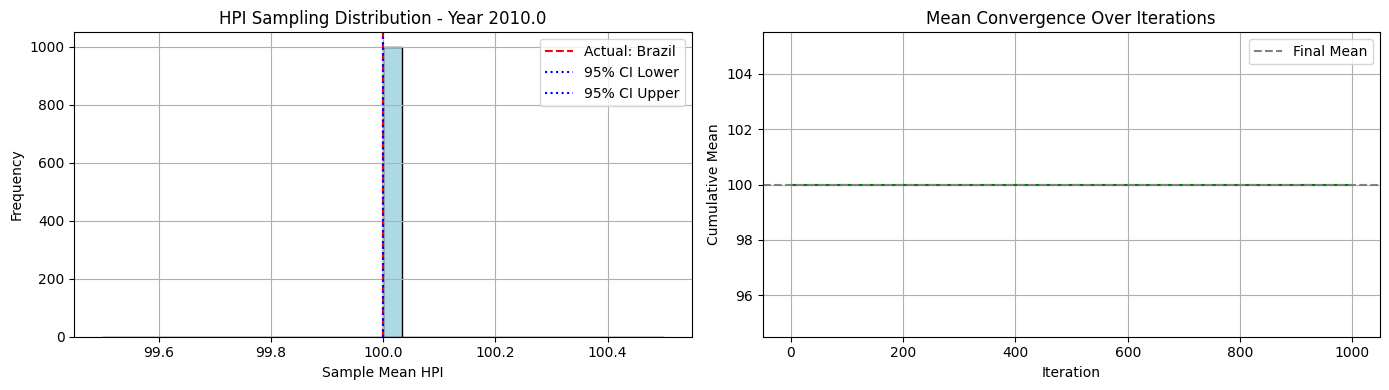


📅 Year 2011.0 - Available HPI values for sampling:
[110.52 107.89 110.52]


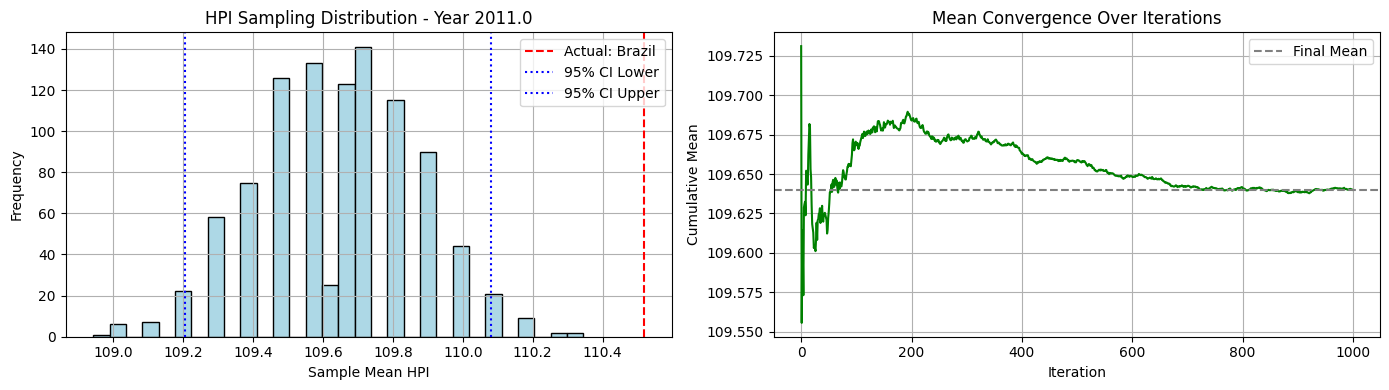


📅 Year 2012.0 - Available HPI values for sampling:
[124.02 118.79 124.02]


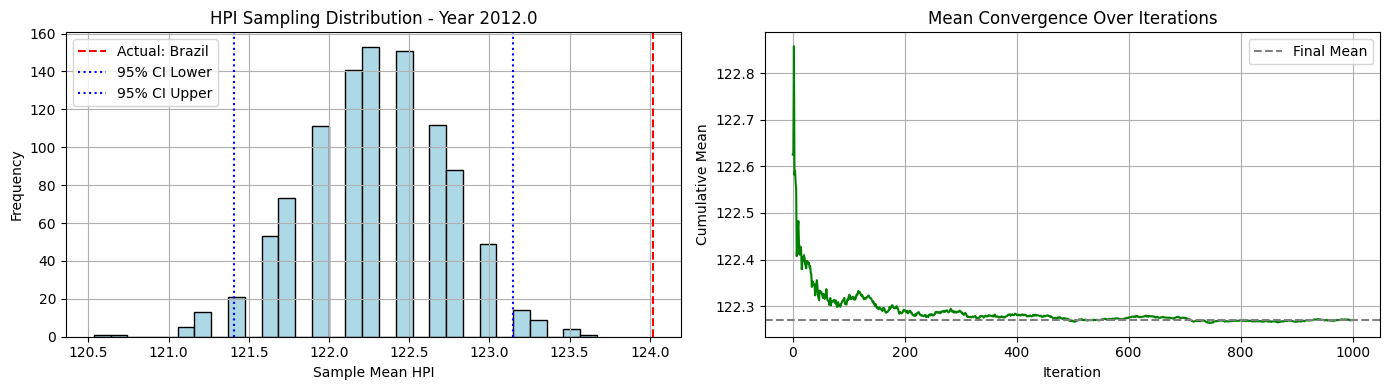


📅 Year 2013.0 - Available HPI values for sampling:
[136.52 130.06 136.52]


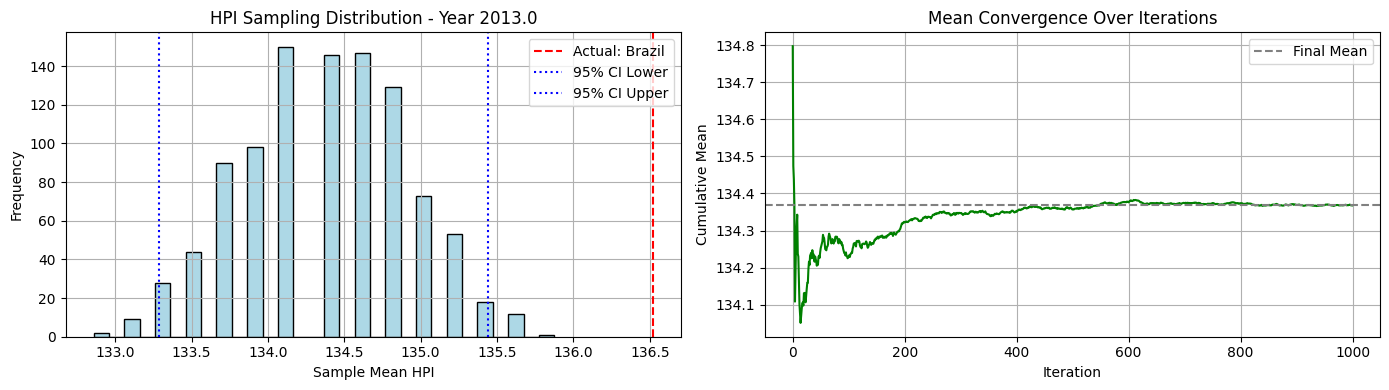


📅 Year 2014.0 - Available HPI values for sampling:
[151.67 140.75 151.67]


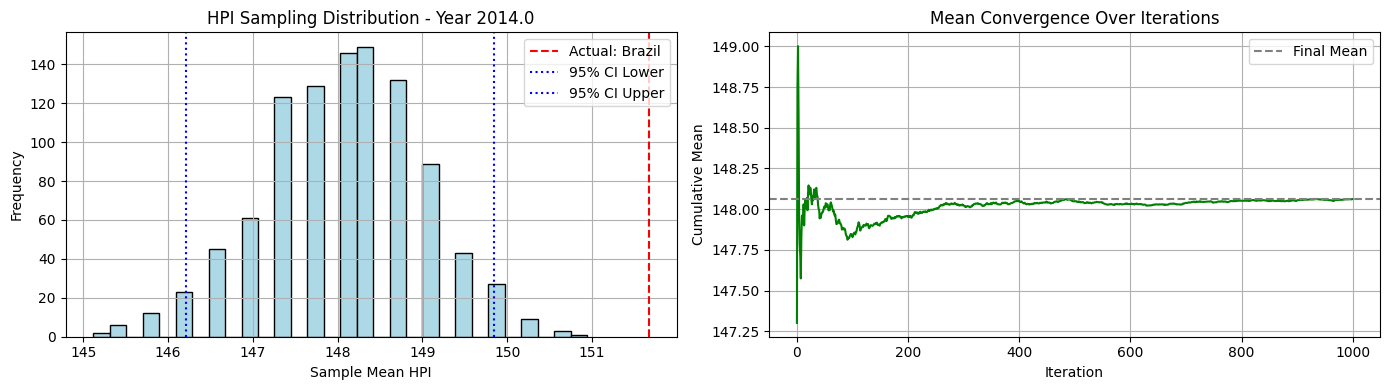


📅 Year 2015.0 - Available HPI values for sampling:
[162.89 152.93 162.89]


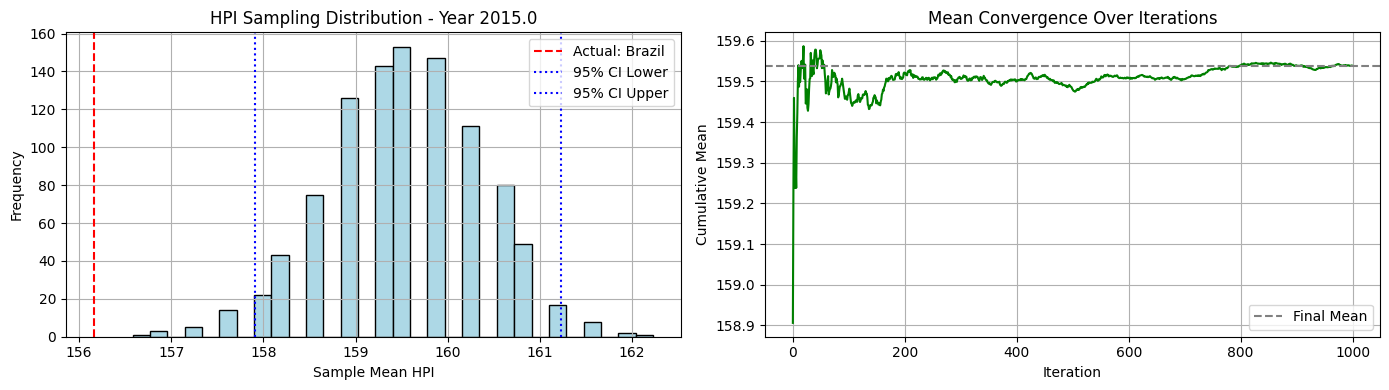


📅 Year 2016.0 - Available HPI values for sampling:
[172.75 167.48 164.18]


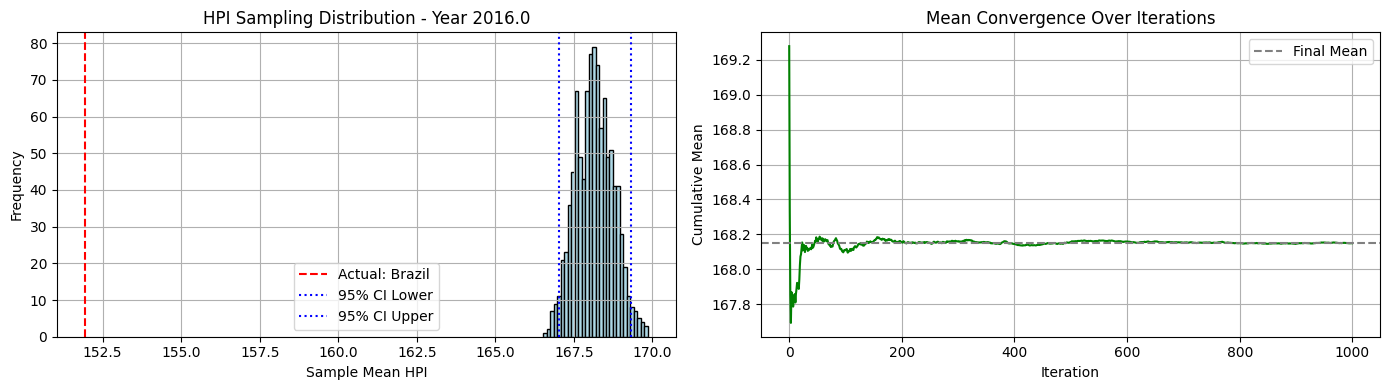


📅 Year 2017.0 - Available HPI values for sampling:
[183.99 178.56 168.  ]


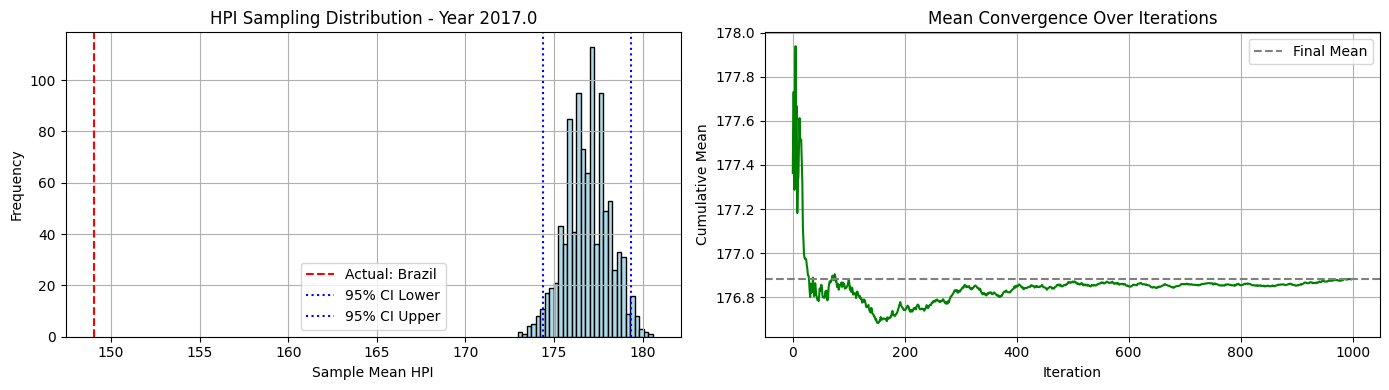


📅 Year 2018.0 - Available HPI values for sampling:
[191.85 188.24 168.42]


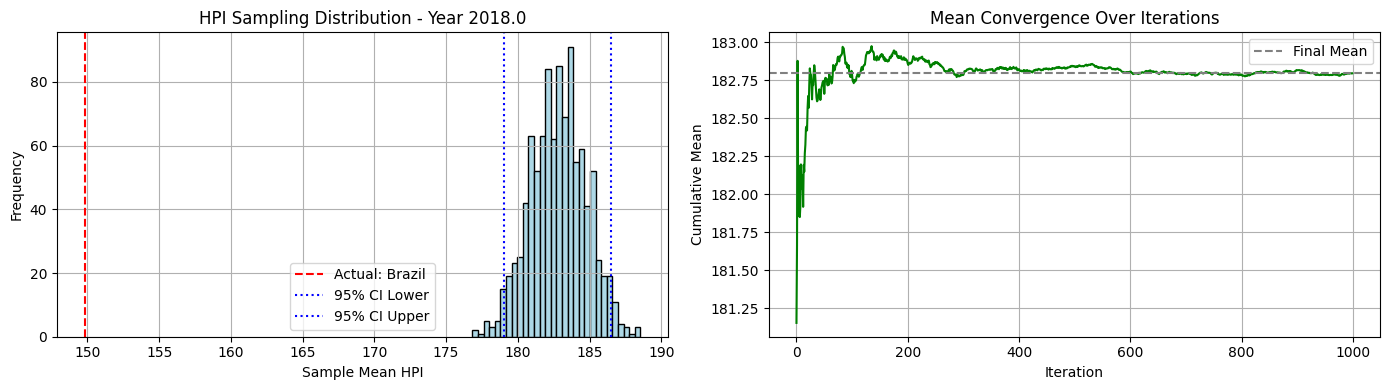


📅 Year 2019.0 - Available HPI values for sampling:
[198.37 198.37 172.03]


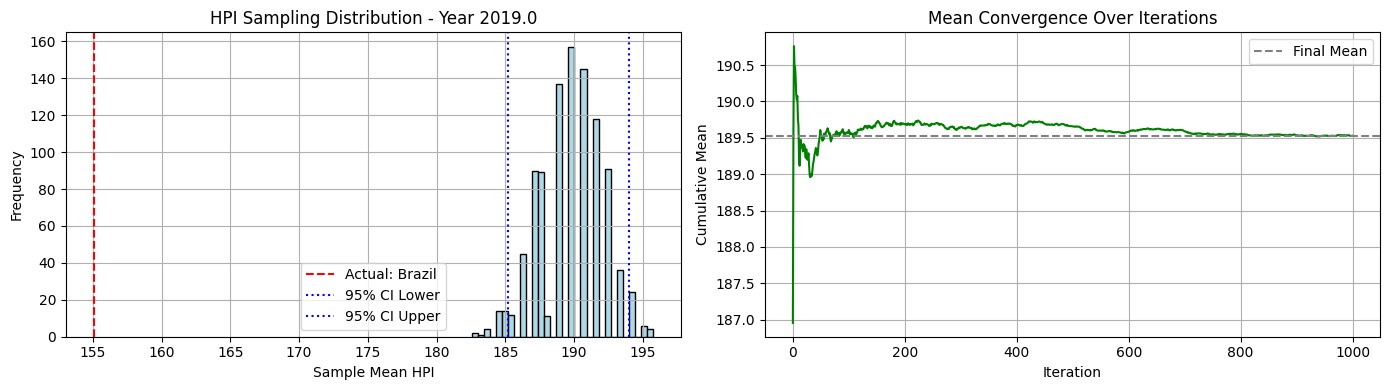


📅 Year 2020.0 - Available HPI values for sampling:
[213.74 203.12 173.67]


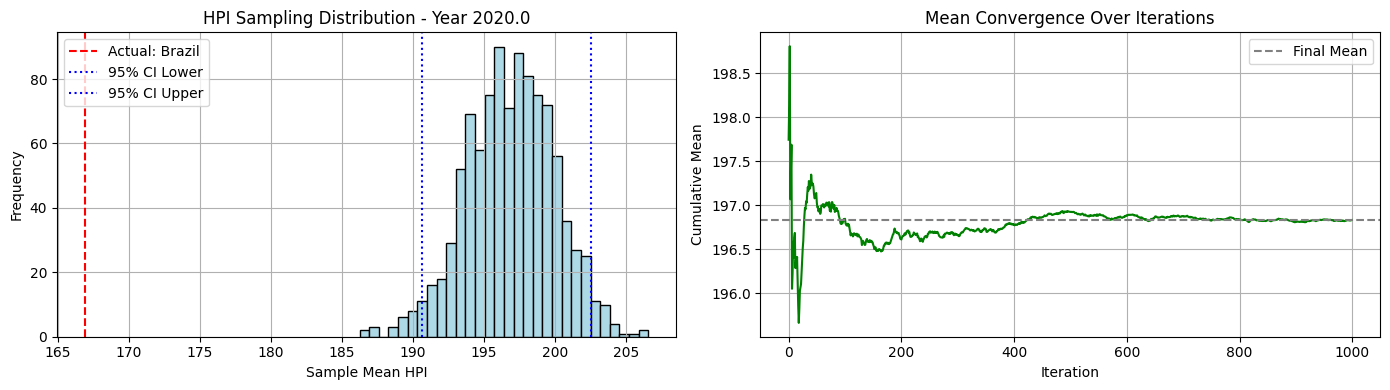


📅 Year 2021.0 - Available HPI values for sampling:
[248.26 214.9  173.6 ]


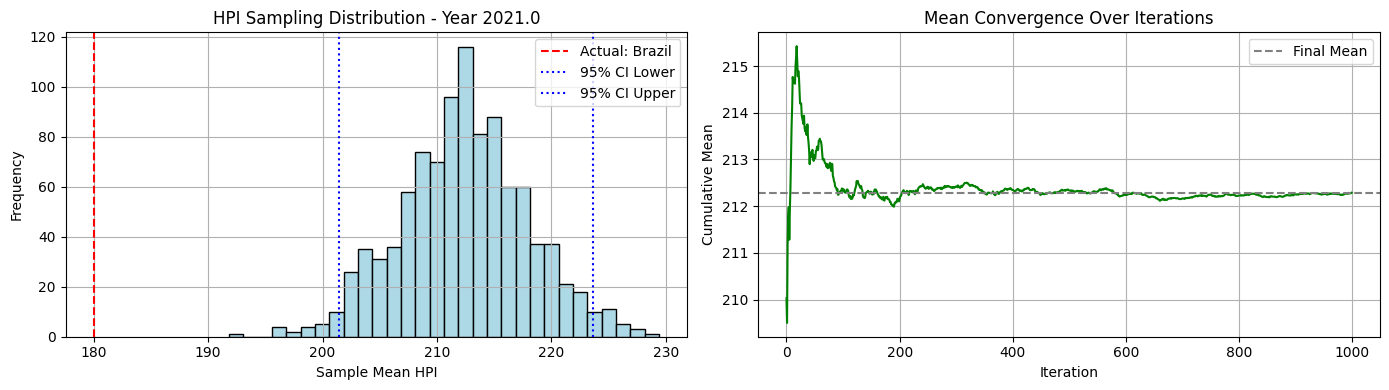


📅 Year 2022.0 - Available HPI values for sampling:
[292.18 230.   172.65]


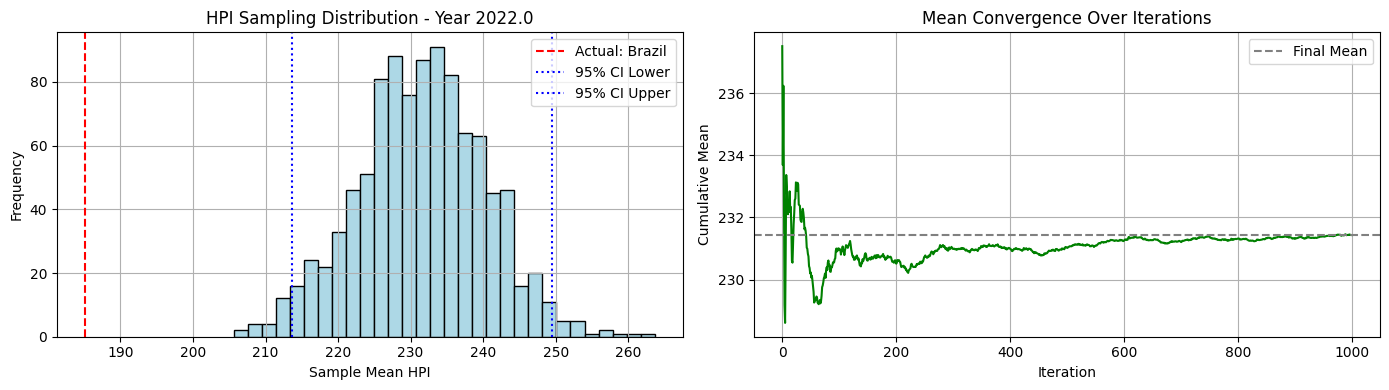


📅 Year 2023.0 - Available HPI values for sampling:
[309.37 245.75 175.16]


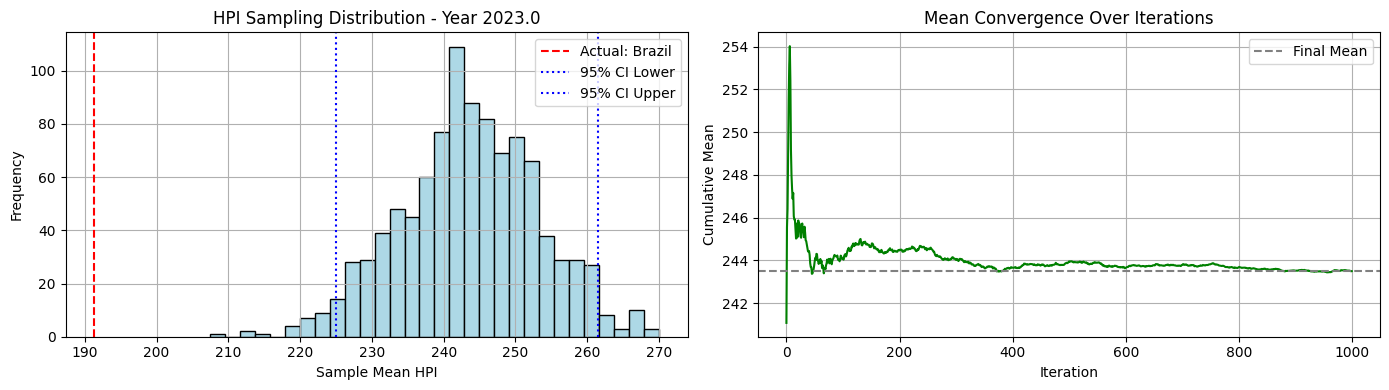


📅 Year 2024.0 - Available HPI values for sampling:
[328.24 269.02 175.38]


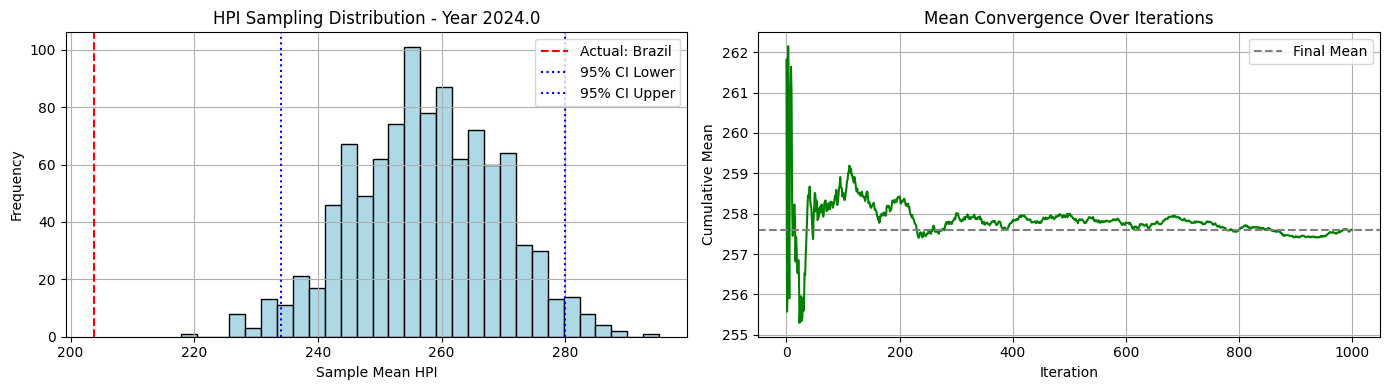

In [20]:
synthetic_south_america, excluded_country_sa, actual_south_america = estimate_hpi_by_continent_sampling(df_hpi, df_info, continent_name='South America', seed=42)

🌍 Continent 'Europe' selected. Excluding country: Finland
📊 Sampling from countries: ['Austria', 'Belgium', 'Bulgaria', 'Croatia', 'Czech-Republic', 'Denmark', 'Estonia', 'France', 'Germany', 'Greece', 'Hungary', 'Iceland', 'Ireland', 'Italy', 'Latvia', 'Lithuania', 'Luxembourg', 'Malta', 'Netherlands', 'Norway', 'Poland', 'Portugal', 'Romania', 'Russia', 'Serbia', 'Slovakia', 'Slovenia', 'Spain', 'Sweden', 'Switzerland', 'United-Kingdom']

📅 Year 2010.0 - Available HPI values for sampling:
[100. 100. 100. 100. 100. 100. 100. 100. 100. 100. 100. 100. 100. 100.
 100. 100. 100. 100. 100. 100. 100. 100. 100. 100. 100. 100. 100. 100.
 100. 100. 100.]


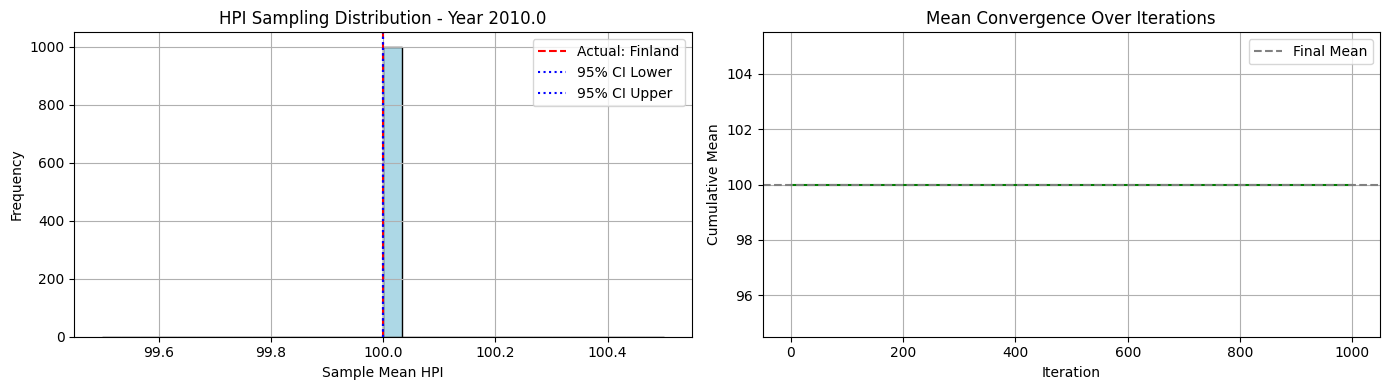


📅 Year 2011.0 - Available HPI values for sampling:
[104.22 103.58  94.49 100.16 100.02  98.29 108.47 105.69 102.42  94.53
  96.56 105.5   94.49 101.36 110.42 106.6  103.68  98.63  98.02 108.01
 100.08  95.1   94.49  94.49  97.62  98.46 102.72  94.49 102.58 107.51
  98.54]


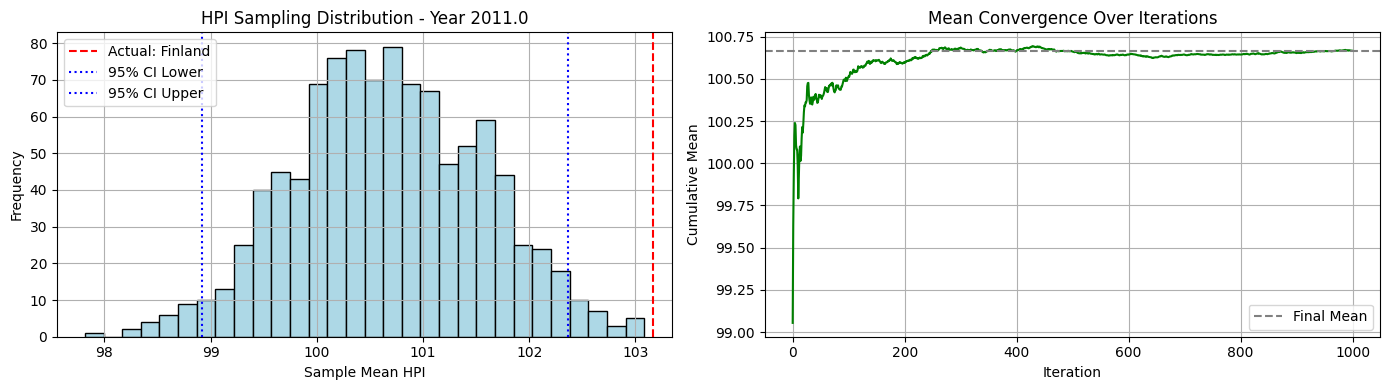


📅 Year 2012.0 - Available HPI values for sampling:
[117.13 106.02  92.69  98.62  98.56  95.67 116.34 105.11 105.48  88.37
  92.98 112.38  88.37  98.77 113.71 106.36 108.03 101.62  91.44 115.34
  96.58  88.37  88.37  91.1   95.68  95.73  95.63  88.37 103.86 113.72
  98.92]


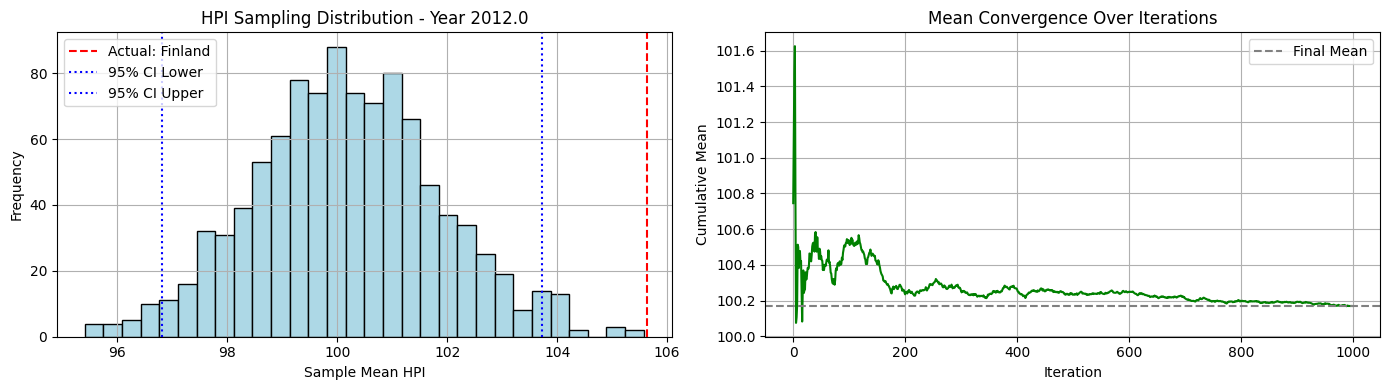


📅 Year 2013.0 - Available HPI values for sampling:
[122.59 107.59  90.65  94.7   98.58  99.37 128.77 103.13 108.68  85.58
  90.58 119.18  85.58  92.38 121.5  107.65 113.42 101.21  85.95 119.98
  92.35  86.7   85.58  94.32  90.62  96.53  90.62  85.58 109.22 118.3
 101.46]


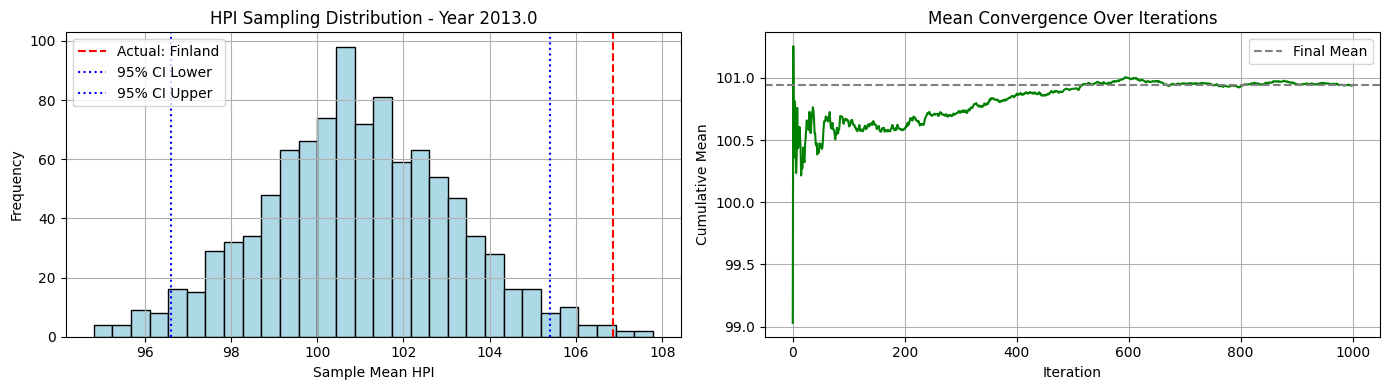


📅 Year 2014.0 - Available HPI values for sampling:
[126.79 107.22  91.95  93.19 101.   103.12 146.41 101.58 111.85  84.64
  94.37 128.94  84.66  88.02 128.78 114.57 118.39 103.79  86.66 123.24
  93.27  90.38  84.64  95.84  95.77  97.8   84.64  84.64 119.52 121.46
 109.6 ]


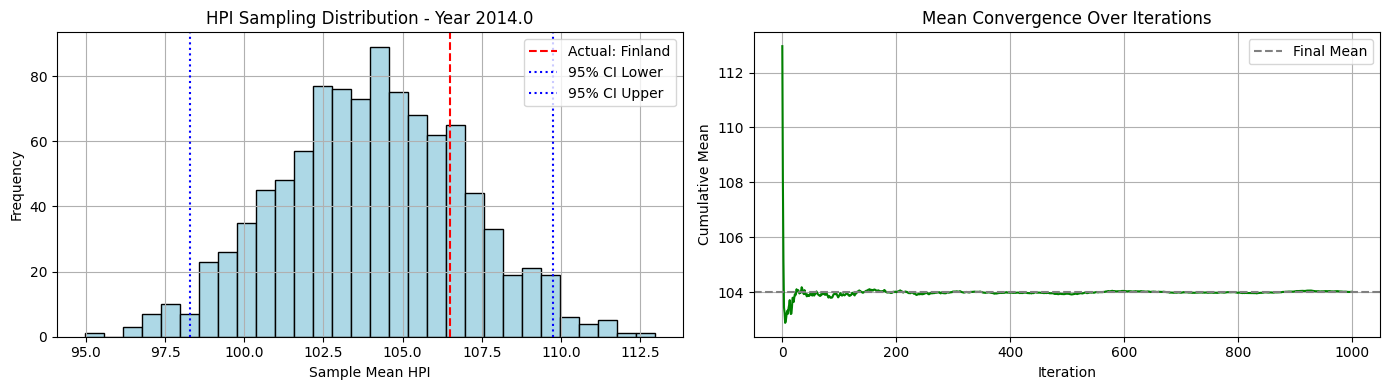


📅 Year 2015.0 - Available HPI values for sampling:
[132.06 109.17  94.51  90.54 105.01 110.29 156.46 100.22 117.12  84.67
 106.75 139.74  94.36  84.67 124.46 118.76 124.78 109.83  89.69 130.76
  94.69  93.15  84.67  97.    99.5  103.    85.32  84.67 135.2  124.08
 116.12]


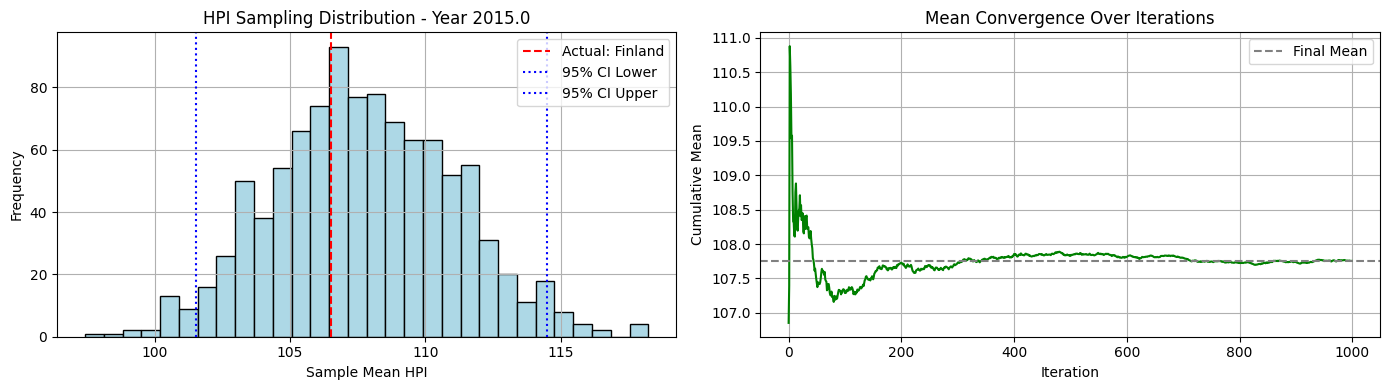


📅 Year 2016.0 - Available HPI values for sampling:
[141.76 111.72 101.15  91.33 112.52 115.5  163.86 101.25 125.93  88.1
 121.03 154.59 101.42  88.1  135.02 125.16 132.28 115.82  94.43 139.95
  96.44  99.78  88.91  91.86 110.62 109.87  88.1   88.1  146.34 124.32
 124.27]


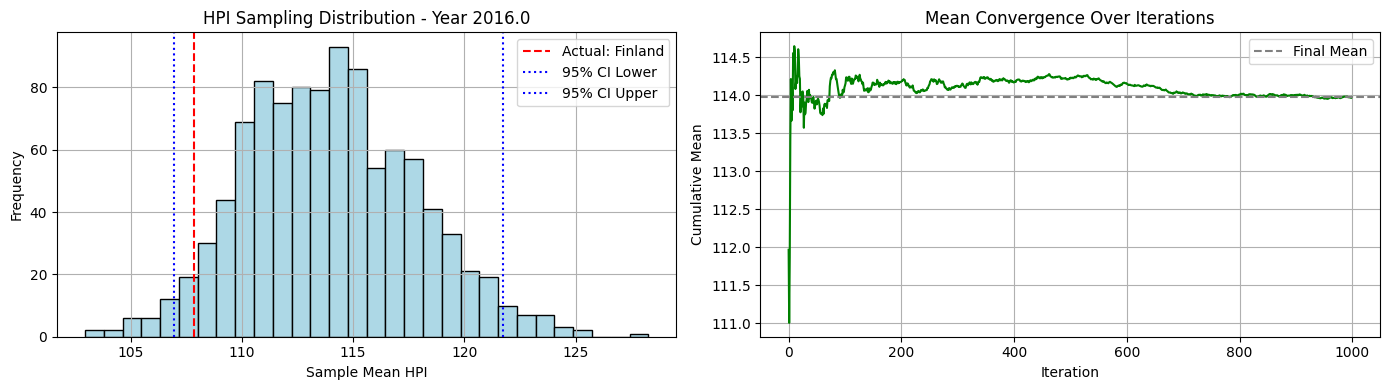


📅 Year 2017.0 - Available HPI values for sampling:
[147.08 115.66 109.91  94.84 125.7  120.63 172.91 104.46 133.62  88.54
 135.84 183.99 112.44  88.54 146.87 136.34 139.69 121.94 102.06 146.91
 100.16 108.99  93.93  88.54 115.3  116.3   95.38  88.54 156.06 125.42
 129.93]


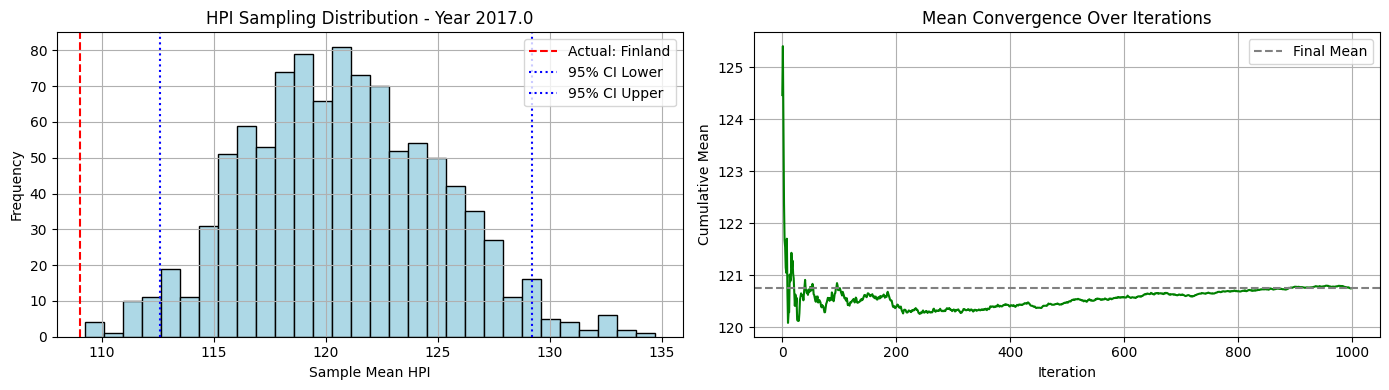


📅 Year 2018.0 - Available HPI values for sampling:
[157.24 119.16 117.15 100.59 136.52 126.31 183.13 107.52 142.52  90.72
 155.3  191.85 123.96  90.72 160.92 146.29 149.55 129.02 111.57 149.04
 106.75 120.19  99.37  90.72 123.06 124.97 103.7   90.72 154.6  129.16
 134.04]


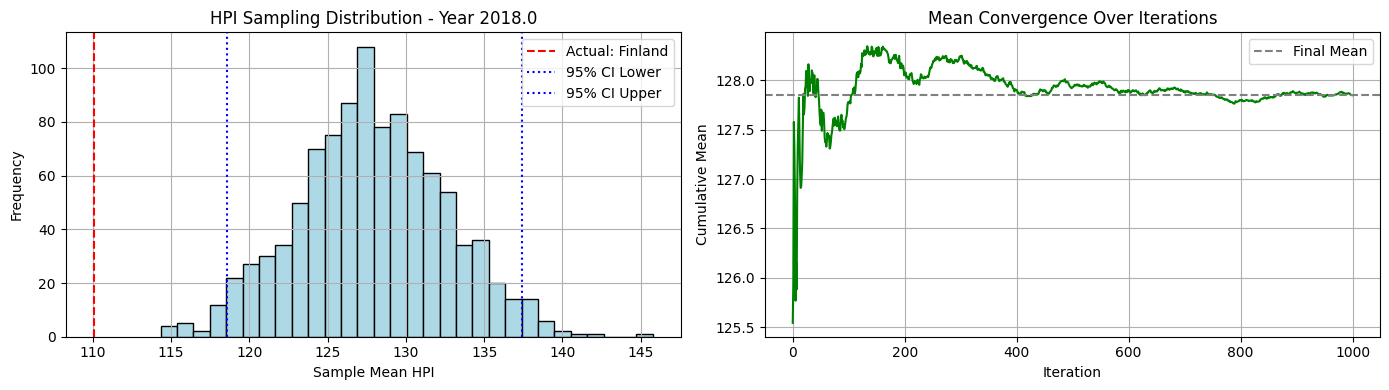


📅 Year 2019.0 - Available HPI values for sampling:
[163.43 123.62 124.2  109.64 149.02 129.62 195.98 111.1  150.75  97.25
 181.64 198.37 126.85  97.25 175.33 156.3  164.68 136.9  119.62 152.73
 116.01 132.16 102.72  97.25 135.77 136.39 110.65  97.25 158.44 133.99
 135.37]


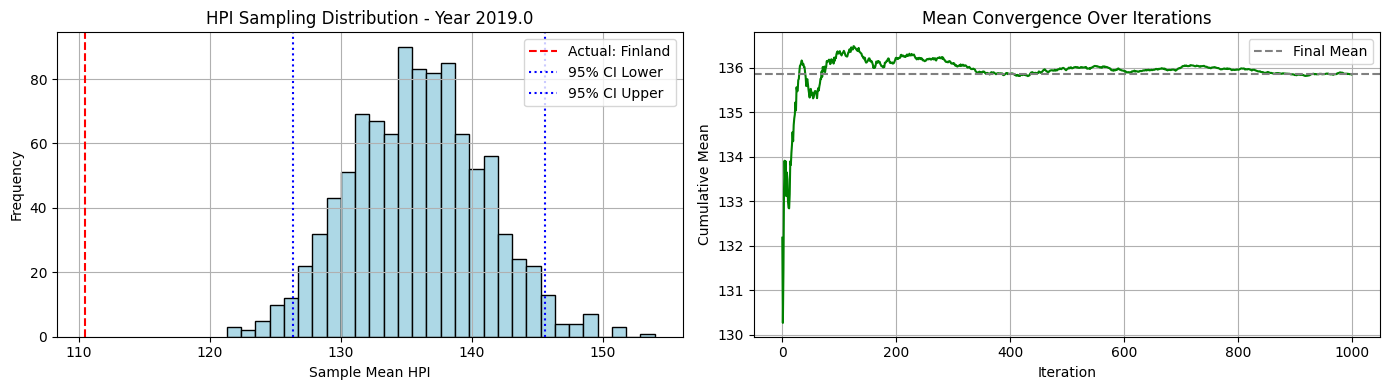


📅 Year 2020.0 - Available HPI values for sampling:
[174.92 128.92 129.87 118.06 161.56 136.24 207.78 116.89 162.48 106.71
 190.63 213.74 127.24 106.71 181.42 167.66 188.57 141.54 129.21 159.24
 128.18 143.75 107.53 106.71 149.28 149.36 115.74 106.71 165.09 137.31
 139.24]


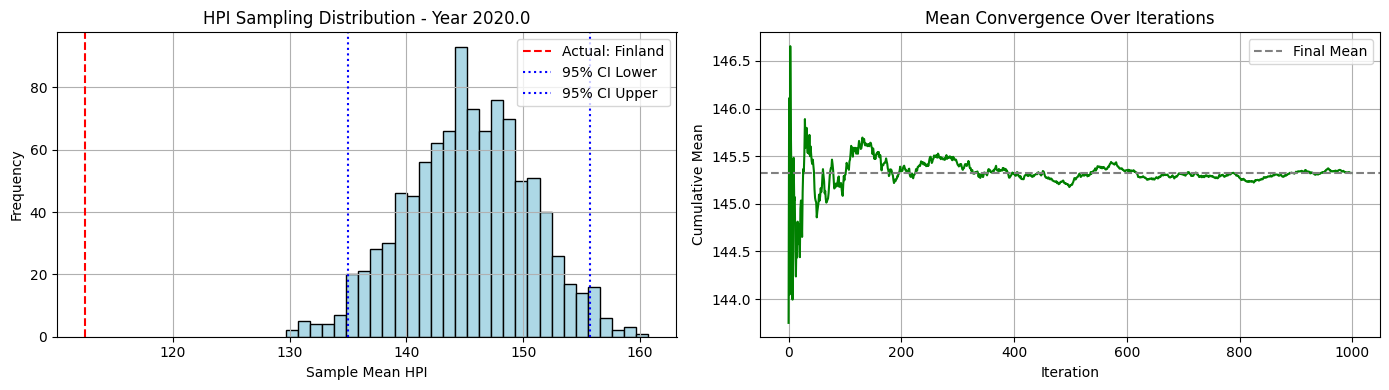


📅 Year 2021.0 - Available HPI values for sampling:
[195.48 137.52 141.14 126.64 193.46 152.2  239.04 124.38 181.28 112.34
 222.1  248.26 137.77 112.34 201.18 194.58 214.81 148.74 147.93 175.91
 139.92 157.27 112.34 121.41 166.04 158.94 129.1  112.34 181.79 145.16
 150.58]


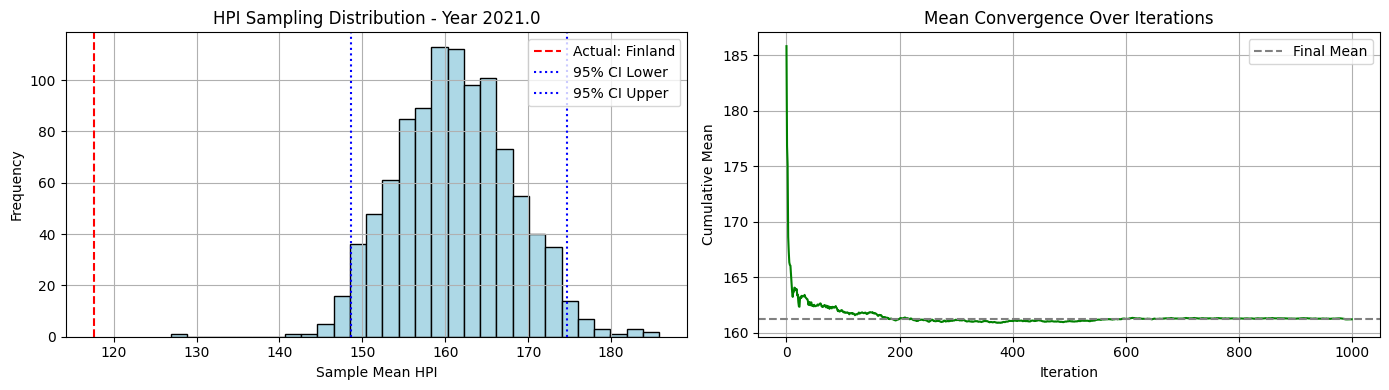


📅 Year 2022.0 - Available HPI values for sampling:
[215.62 145.12 160.59 145.44 226.15 151.49 292.18 132.1  190.42 118.98
 271.5  292.18 154.73 118.98 229.01 231.64 235.34 158.62 167.57 185.13
 156.43 177.14 120.29 155.16 191.49 180.7  148.16 118.98 188.27 154.42
 164.55]


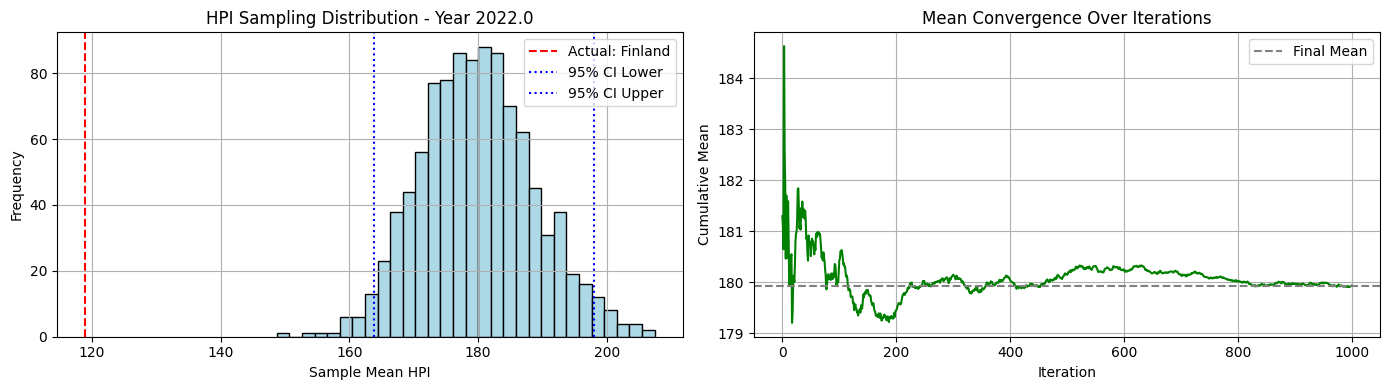


📅 Year 2023.0 - Available HPI values for sampling:
[212.08 148.52 176.43 162.82 222.4  151.24 309.37 131.52 174.25 112.27
 290.98 309.37 159.48 112.27 237.56 254.38 214.   168.5  164.36 184.12
 170.23 191.66 124.06 157.88 209.99 180.36 158.88 112.27 178.36 157.81
 165.  ]


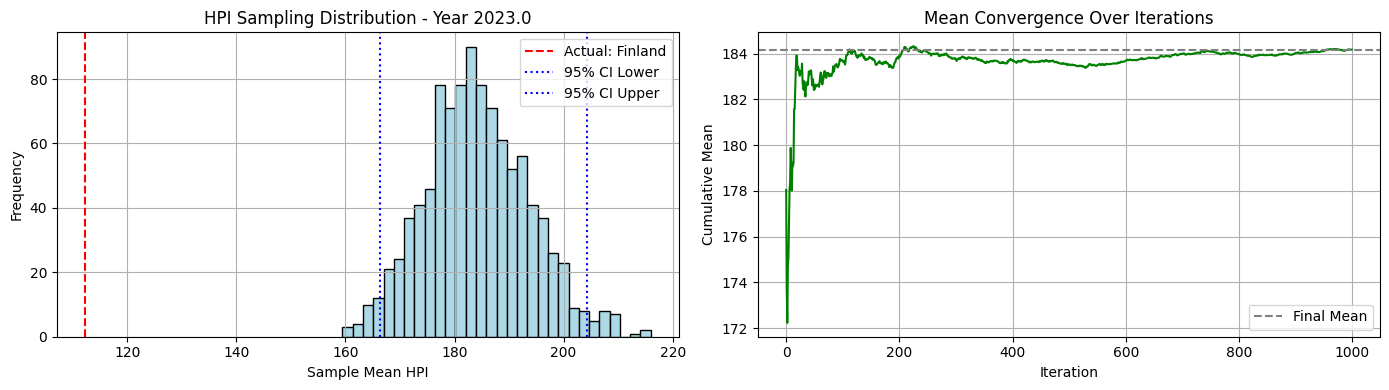


📅 Year 2024.0 - Available HPI values for sampling:
[207.62 153.31 205.53 179.7  233.42 156.73 328.24 126.68 171.5  119.1
 328.1  328.24 173.07 119.1  247.54 279.12 202.74 179.35 177.7  189.05
 195.72 209.06 130.34 186.66 220.7  187.15 170.56 119.1  178.49 160.56
 166.38]


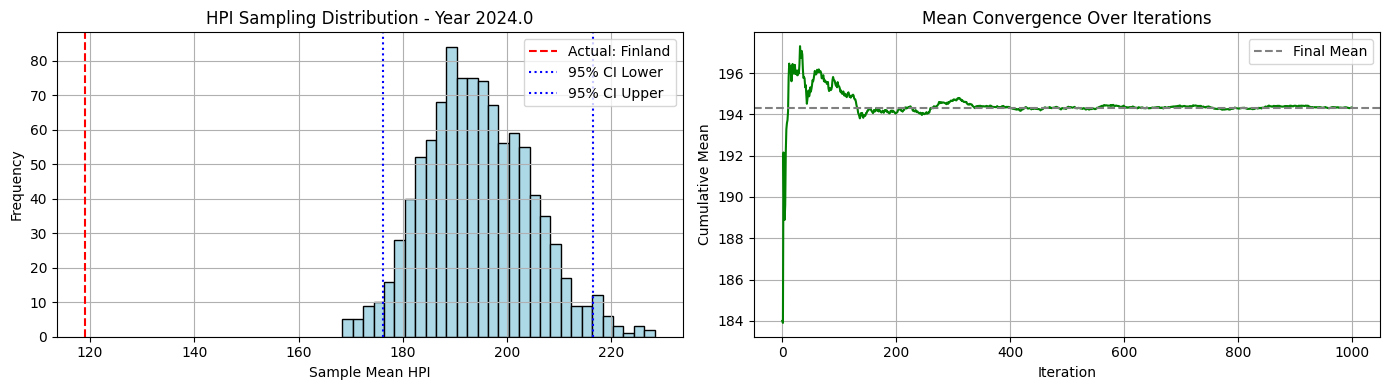

In [11]:
synthetic_europe, excluded_country_eu, actual_europe = estimate_hpi_by_continent_sampling(df_hpi, df_info, continent_name='Europe', seed=42)

🌍 Continent 'North America' selected. Excluding country: USA
📊 Sampling from countries: ['Canada', 'Mexico']

📅 Year 2010.0 - Available HPI values for sampling:
[100. 100.]


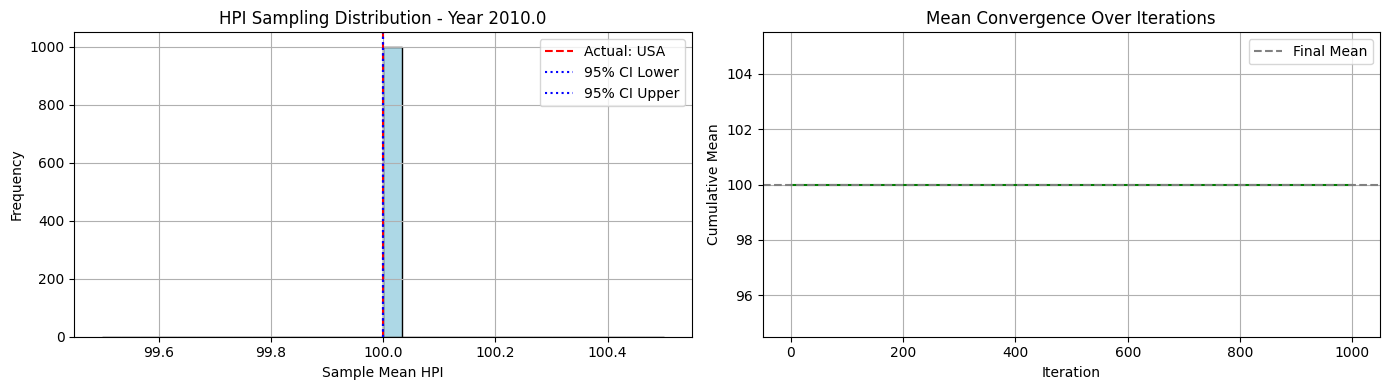


📅 Year 2011.0 - Available HPI values for sampling:
[105.75 105.8 ]


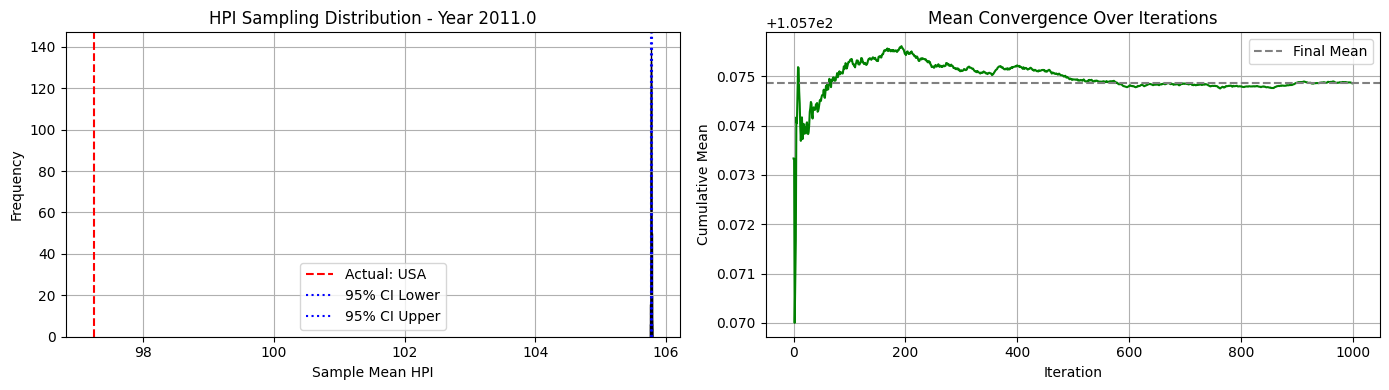


📅 Year 2012.0 - Available HPI values for sampling:
[110.62 109.17]


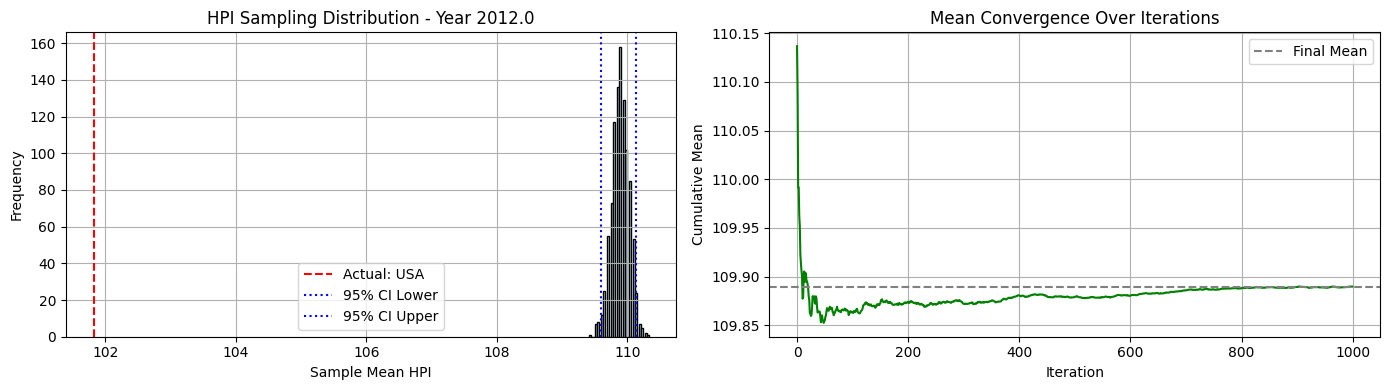


📅 Year 2013.0 - Available HPI values for sampling:
[112.76 114.75]


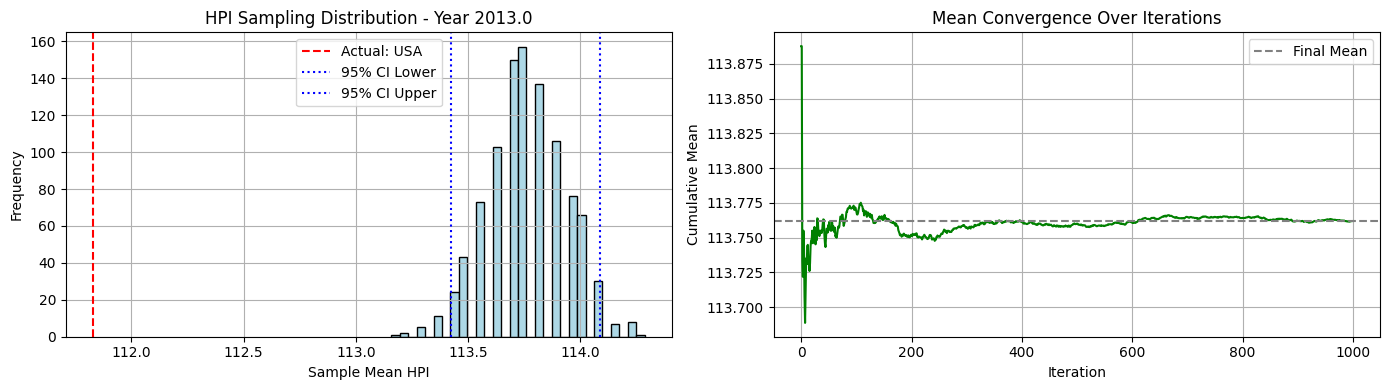


📅 Year 2014.0 - Available HPI values for sampling:
[118.86 119.64]


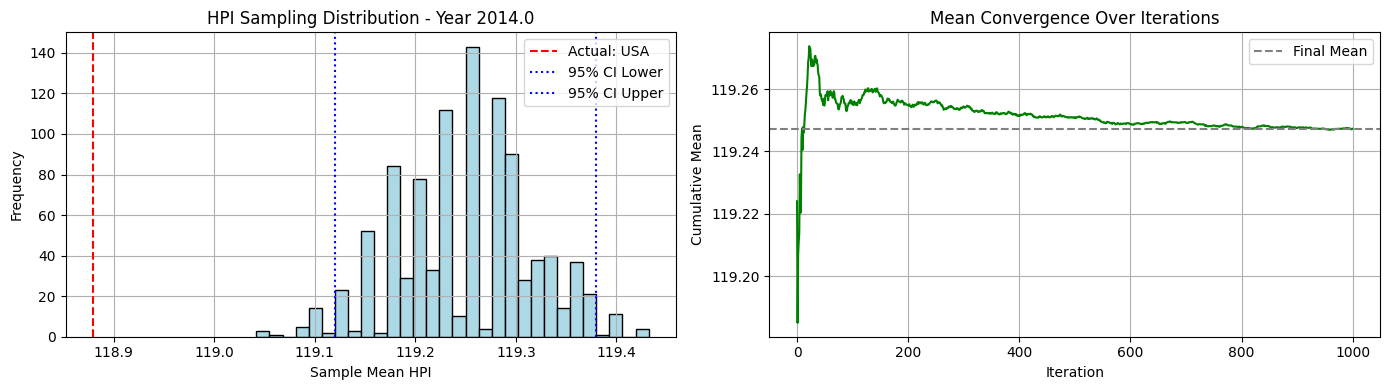


📅 Year 2015.0 - Available HPI values for sampling:
[128.43 129.39]


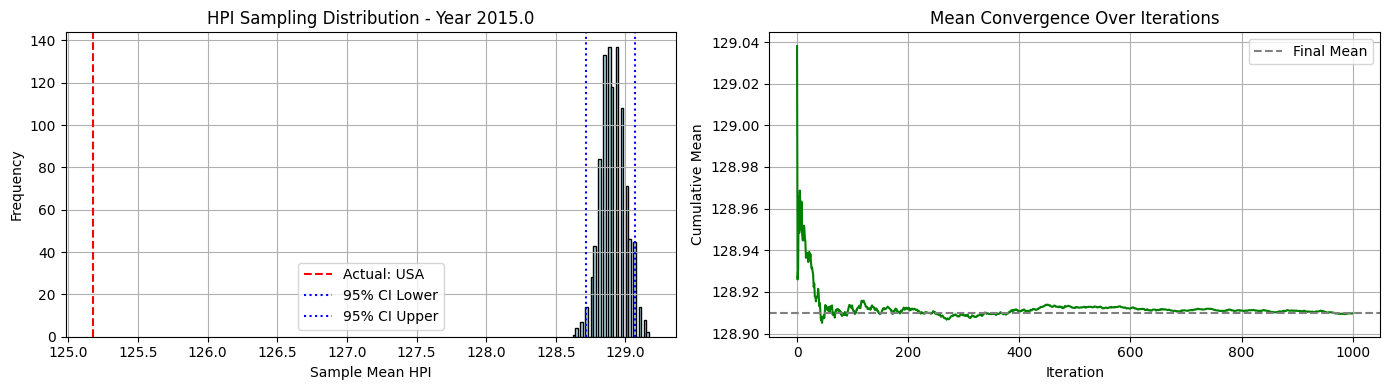


📅 Year 2016.0 - Available HPI values for sampling:
[148.66 138.82]


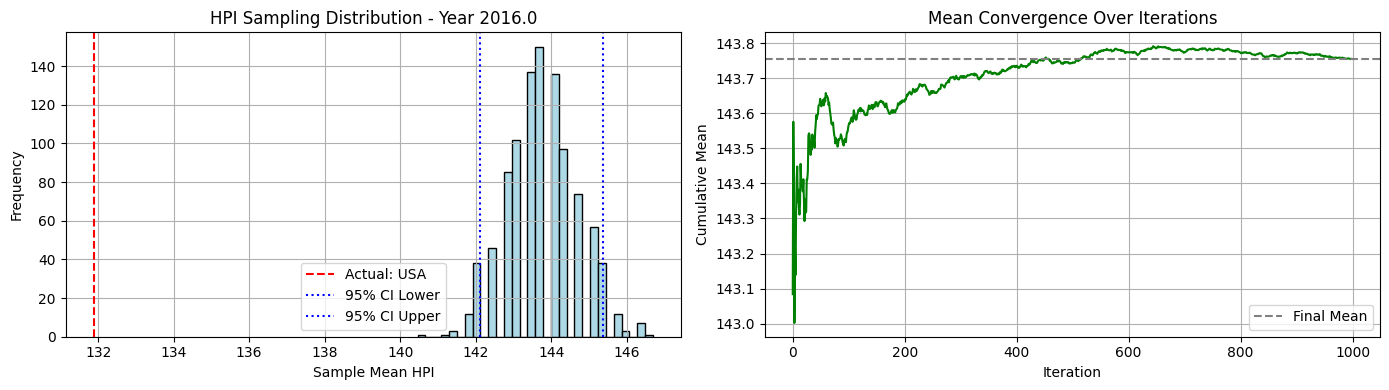


📅 Year 2017.0 - Available HPI values for sampling:
[172.3  149.69]


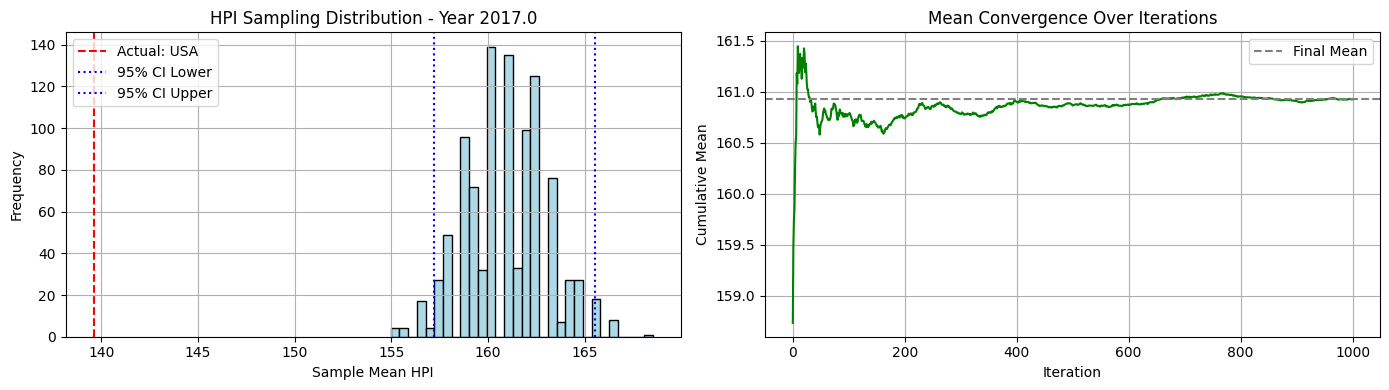


📅 Year 2018.0 - Available HPI values for sampling:
[178.24 162.97]


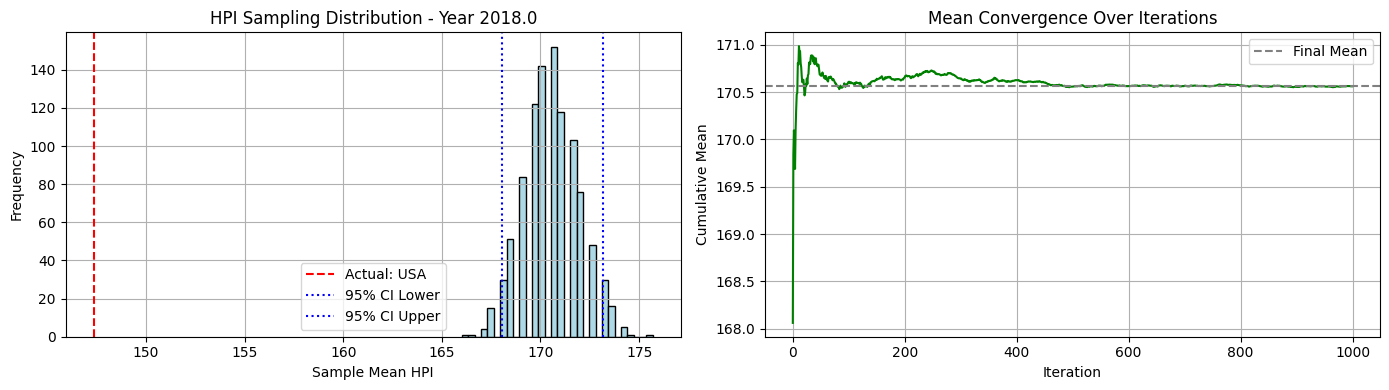


📅 Year 2019.0 - Available HPI values for sampling:
[179.4  176.92]


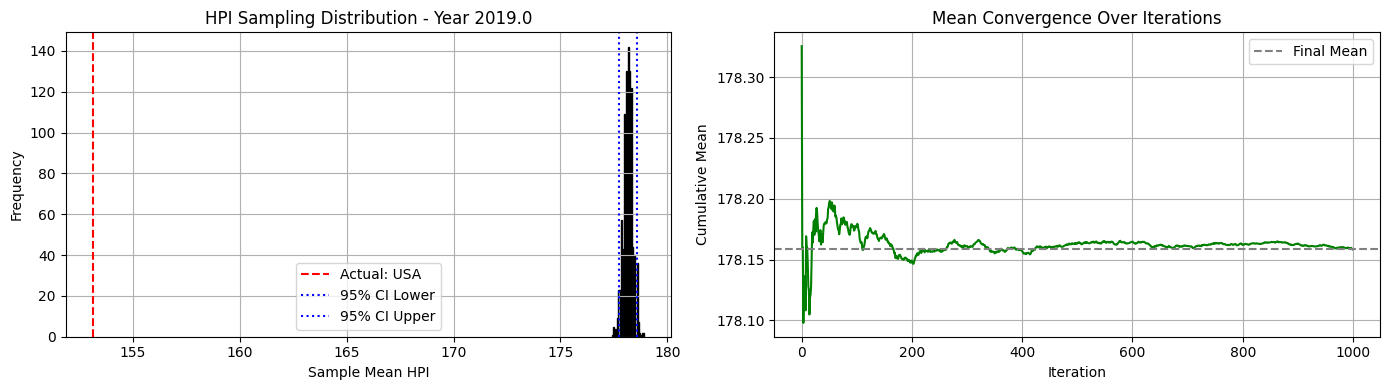


📅 Year 2020.0 - Available HPI values for sampling:
[190.73 187.18]


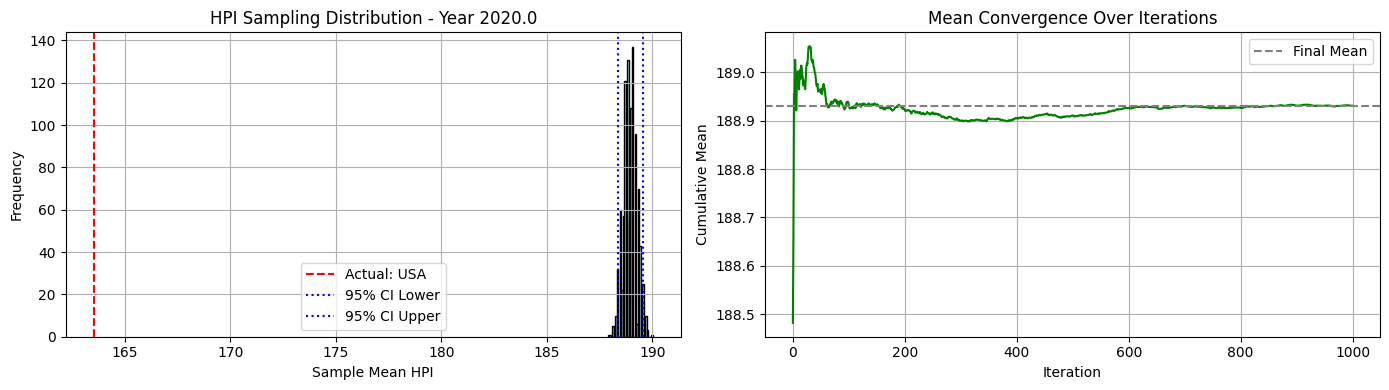


📅 Year 2021.0 - Available HPI values for sampling:
[214.88 201.94]


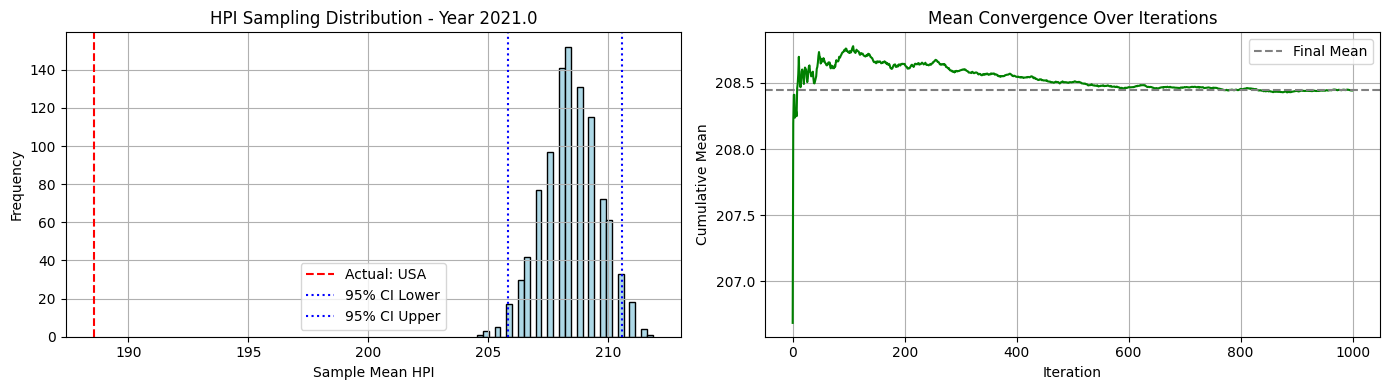


📅 Year 2022.0 - Available HPI values for sampling:
[235.32 219.93]


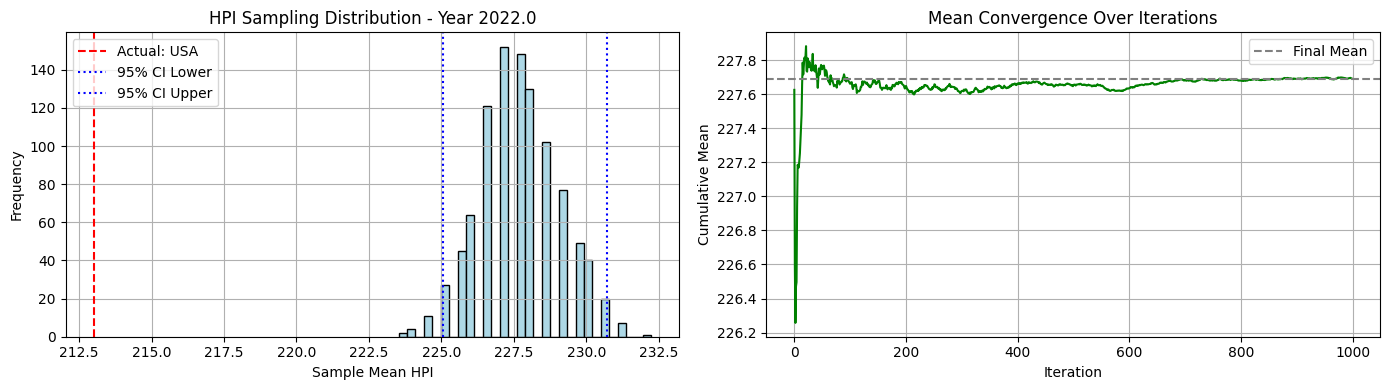


📅 Year 2023.0 - Available HPI values for sampling:
[221.05 243.89]


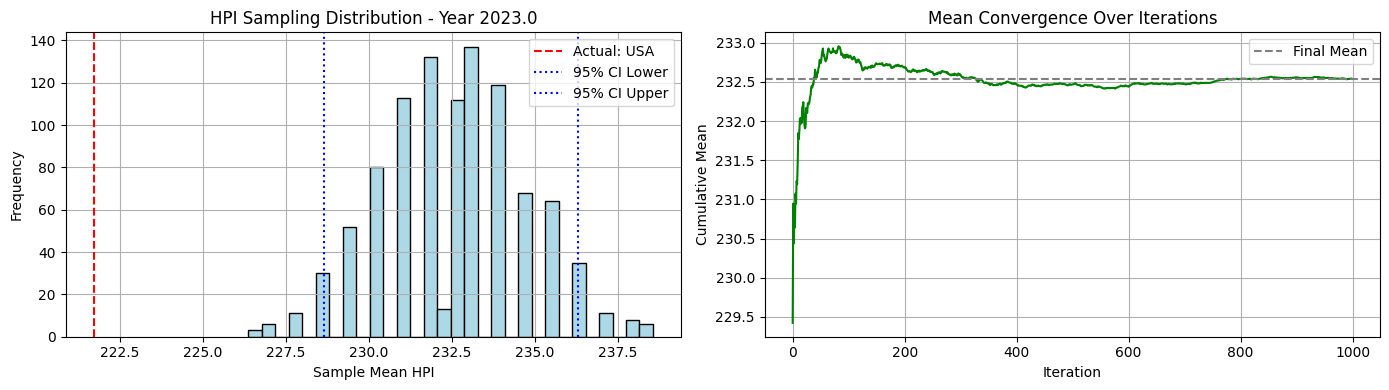


📅 Year 2024.0 - Available HPI values for sampling:
[217.35 266.38]


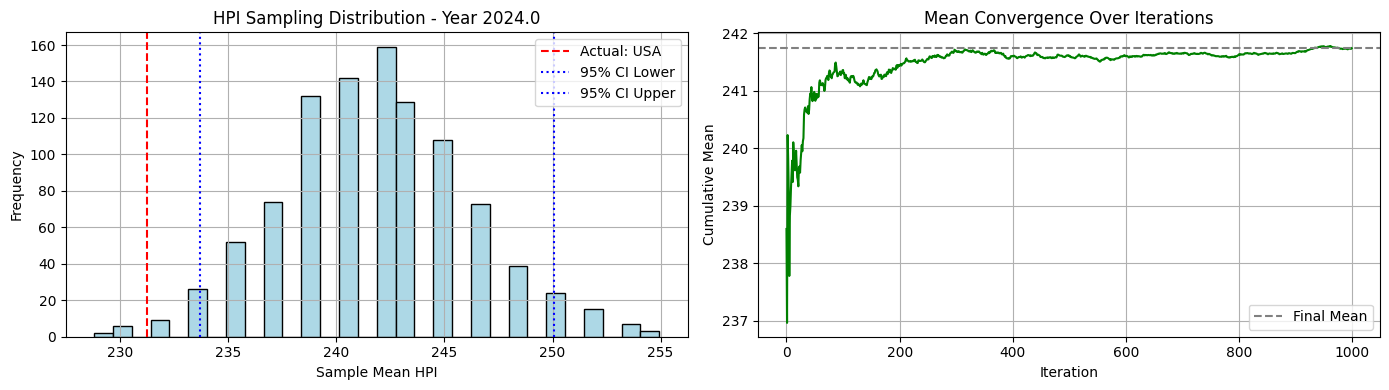

In [12]:
synthetic_north_america, excluded_country_na, actual_north_america = estimate_hpi_by_continent_sampling(df_hpi, df_info, continent_name='North America', seed=42)

🌍 Continent 'Asia' selected. Excluding country: India
📊 Sampling from countries: ['Cyprus', 'Israel', 'Japan', 'Malaysia', 'Philippines', 'Singapore', 'South-Korea', 'Thailand', 'Turkey']

📅 Year 2010.0 - Available HPI values for sampling:
[100. 100. 100. 100. 100. 100. 100. 100. 100.]


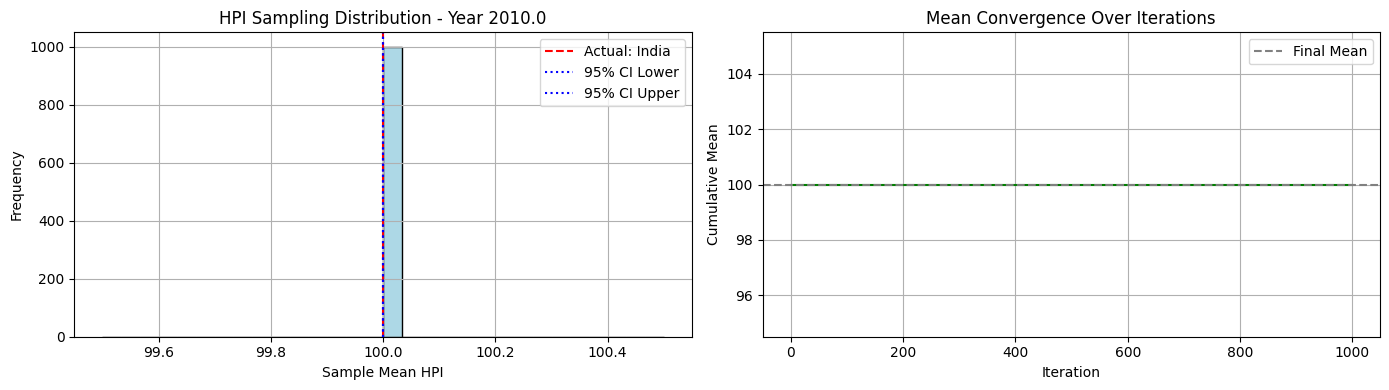


📅 Year 2011.0 - Available HPI values for sampling:
[ 96.68 110.52 100.07 109.83 105.57 109.46 105.23 104.26 108.8 ]


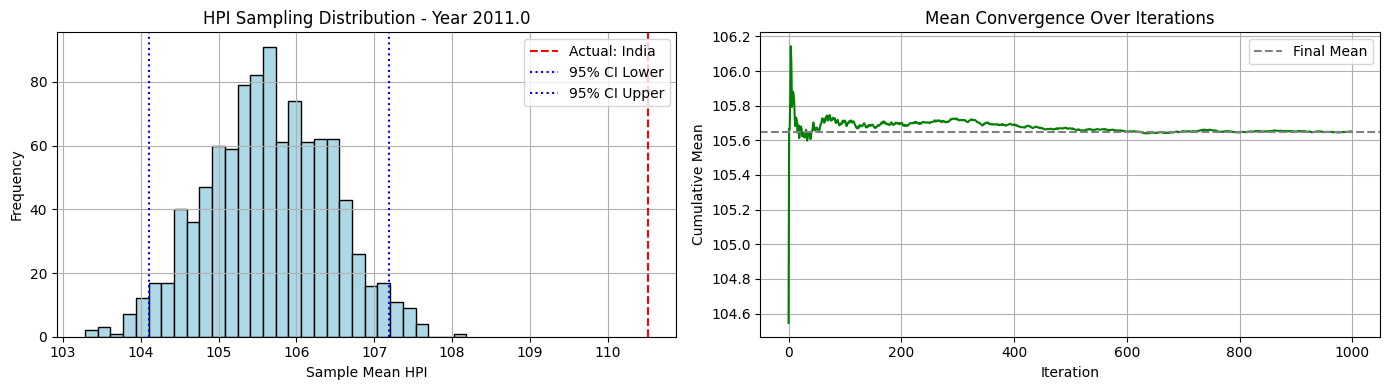


📅 Year 2012.0 - Available HPI values for sampling:
[ 91.54 114.1   99.19 124.02 114.94 112.02 108.25 107.63 120.68]


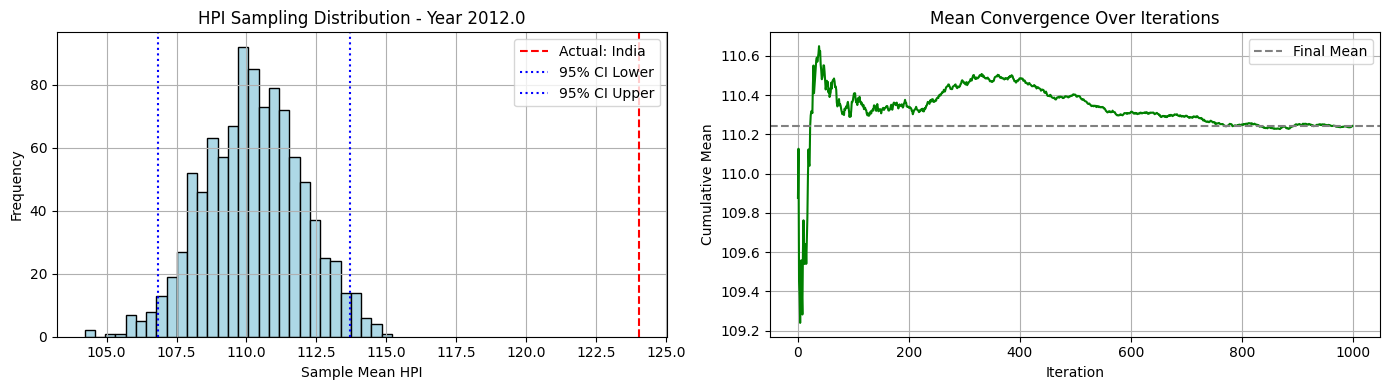


📅 Year 2013.0 - Available HPI values for sampling:
[ 85.58 124.45 100.81 136.52 127.86 115.56 107.8  115.99 134.46]


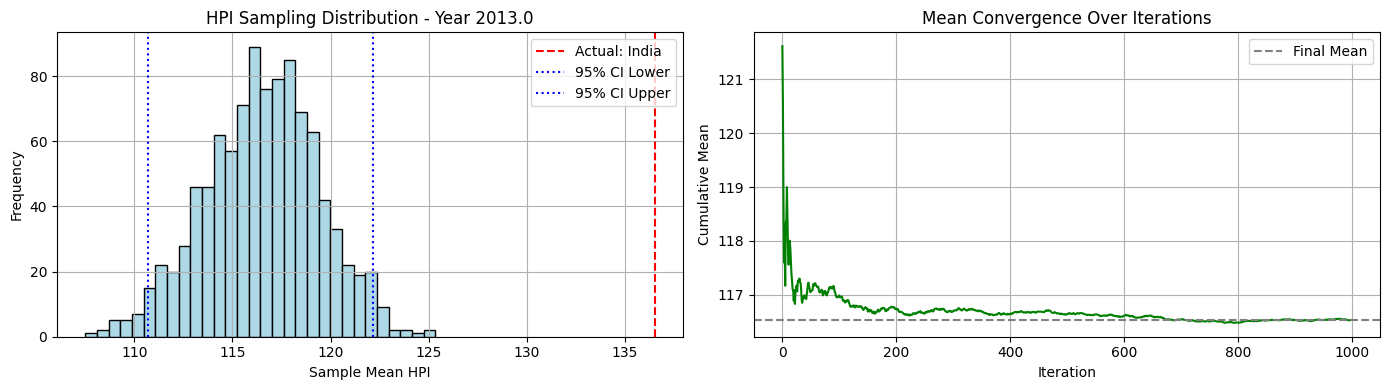


📅 Year 2014.0 - Available HPI values for sampling:
[ 84.64 132.36 102.38 151.67 142.76 112.25 109.43 127.07 151.25]


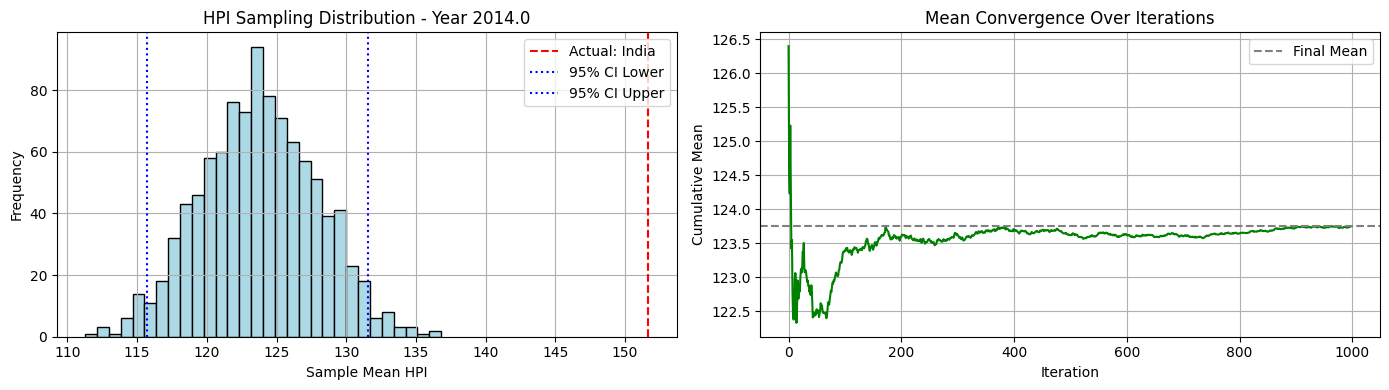


📅 Year 2015.0 - Available HPI values for sampling:
[ 84.67 140.12 104.86 162.89 157.04 107.92 113.08 136.   162.89]


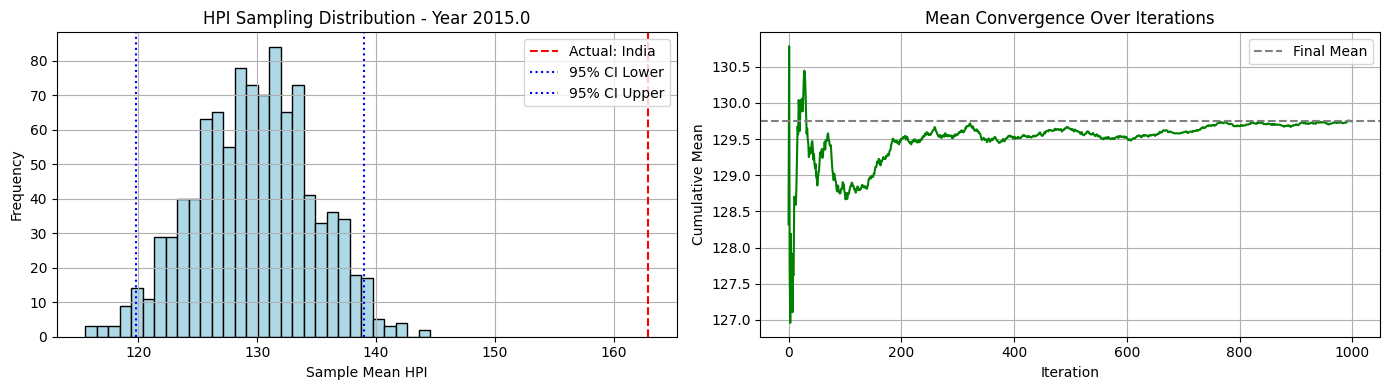


📅 Year 2016.0 - Available HPI values for sampling:
[ 88.1  150.56 107.18 172.75 172.75 104.55 116.09 142.4  172.75]


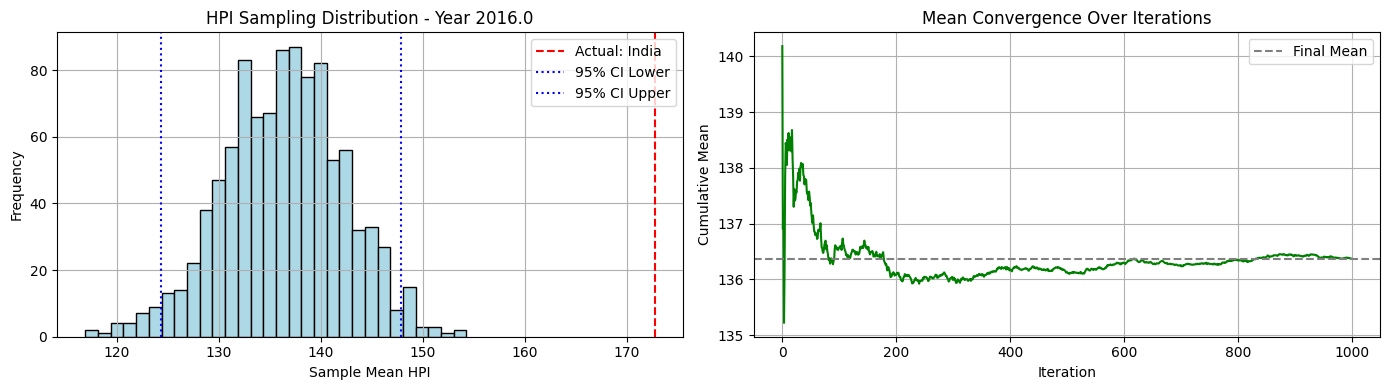


📅 Year 2017.0 - Available HPI values for sampling:
[ 88.54 156.44 109.91 183.99 178.82 103.4  117.6  146.48 183.99]


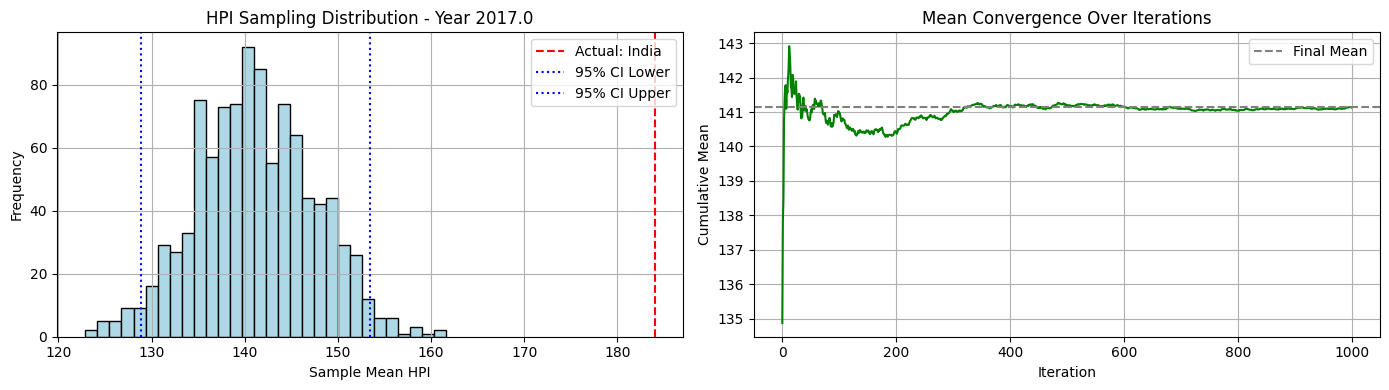


📅 Year 2018.0 - Available HPI values for sampling:
[ 90.72 155.14 112.04 191.85 183.82 111.46 120.22 153.9  191.85]


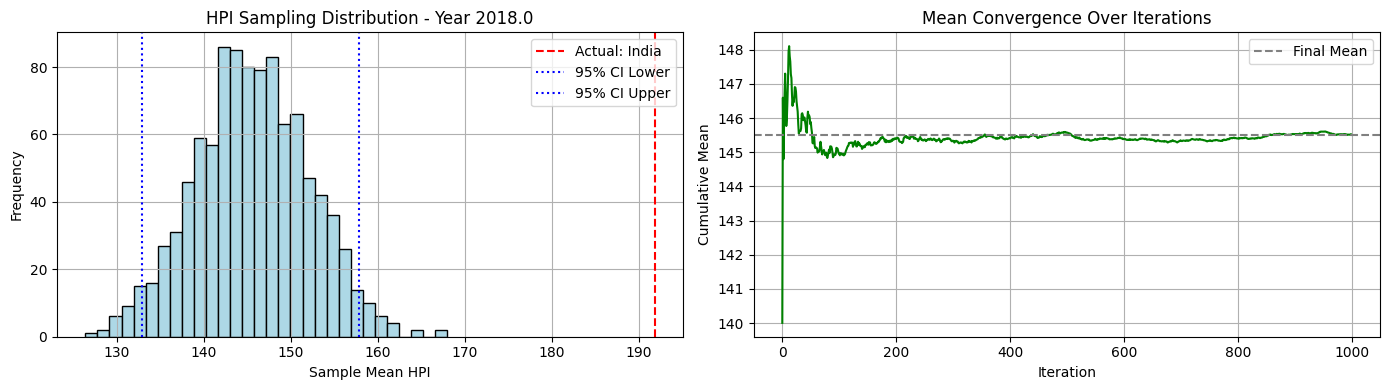


📅 Year 2019.0 - Available HPI values for sampling:
[ 97.25 158.06 113.84 196.06 195.26 113.98 121.93 155.1  198.37]


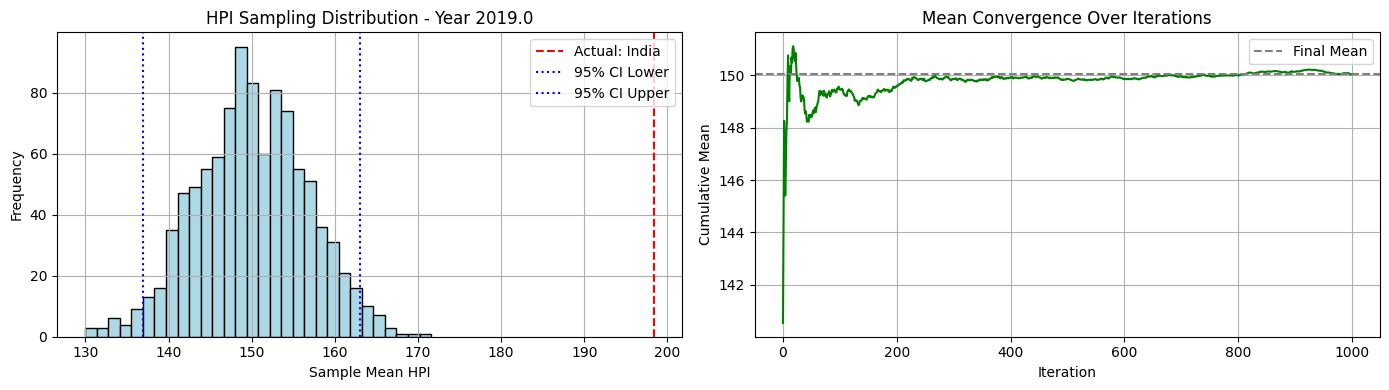


📅 Year 2020.0 - Available HPI values for sampling:
[106.71 162.9  113.93 198.37 213.74 115.8  126.56 160.6  213.74]


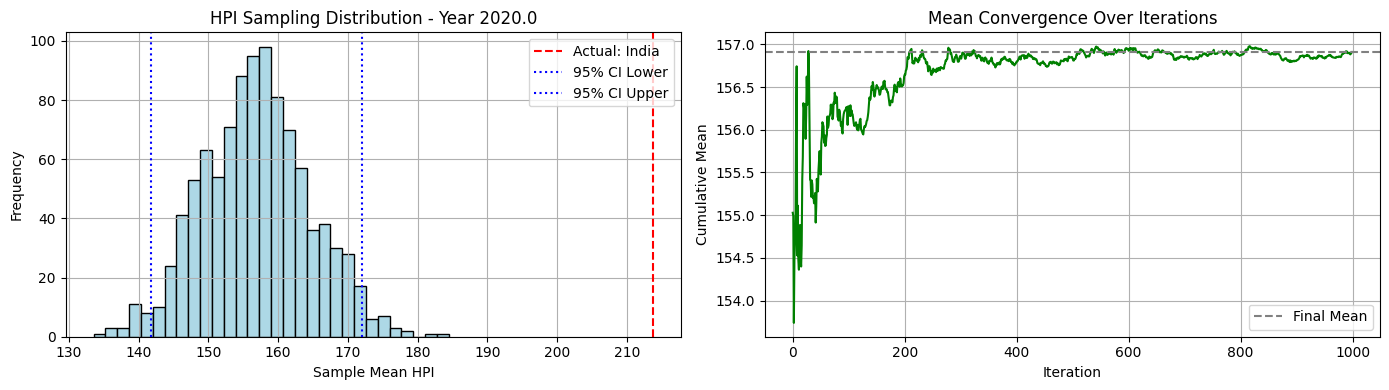


📅 Year 2021.0 - Available HPI values for sampling:
[112.34 176.65 120.7  200.69 211.74 125.04 143.73 164.23 248.26]


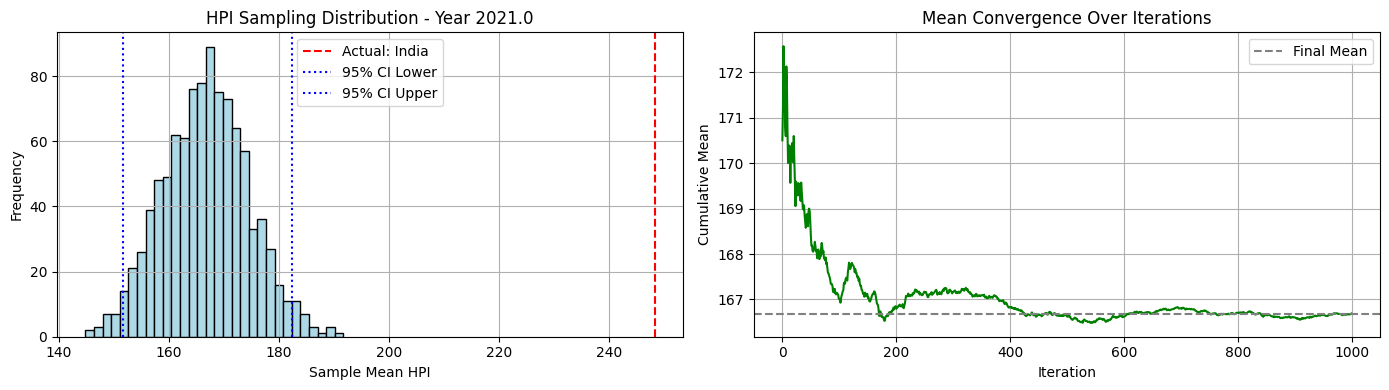


📅 Year 2022.0 - Available HPI values for sampling:
[118.98 207.16 130.84 207.75 223.73 137.74 153.22 169.16 292.18]


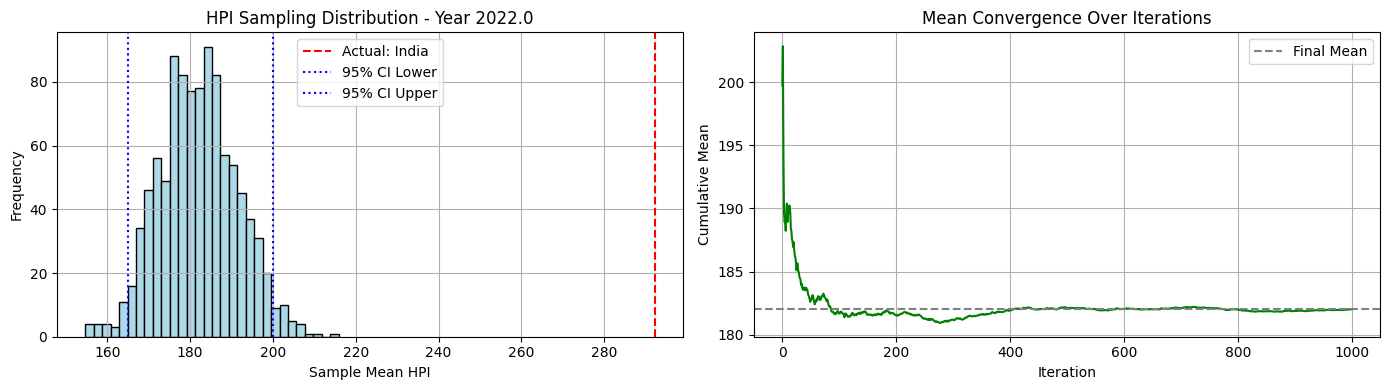


📅 Year 2023.0 - Available HPI values for sampling:
[112.27 214.23 134.8  216.19 248.04 148.01 143.99 174.79 309.37]


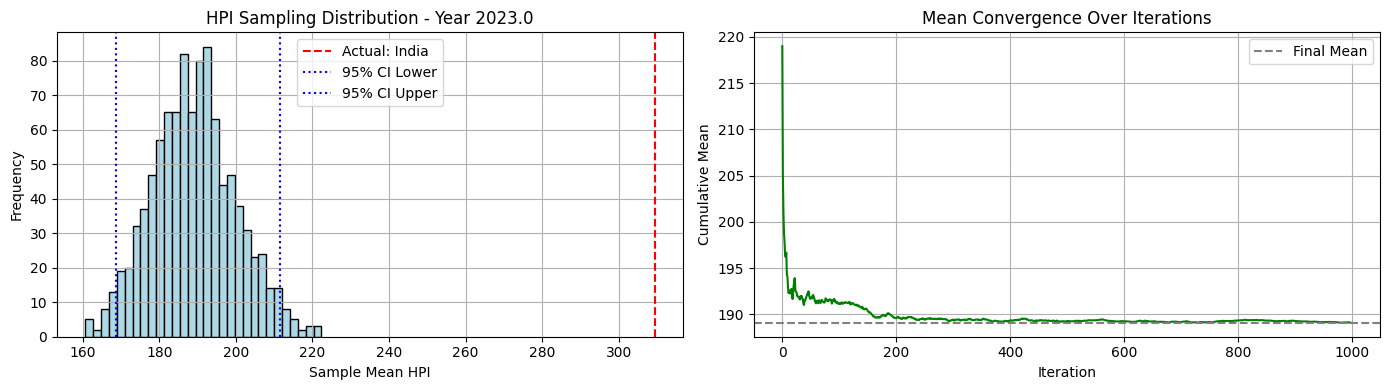


📅 Year 2024.0 - Available HPI values for sampling:
[119.1  224.54 138.61 225.06 256.03 155.12 142.46 178.06 328.24]


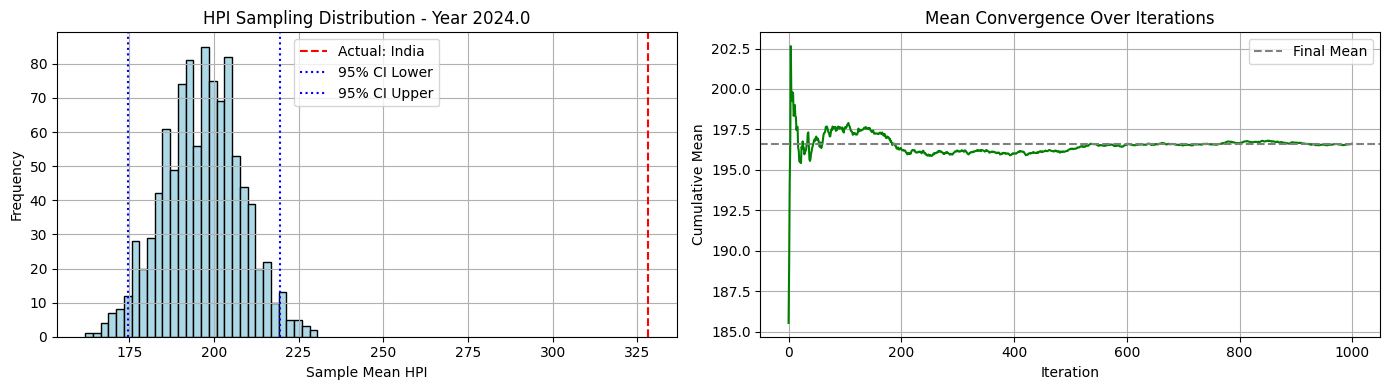

In [13]:
synthetic_asia, excluded_country_asia, actual_asia = estimate_hpi_by_continent_sampling(df_hpi, df_info, continent_name='Asia', seed=42)

In [14]:
synthetic_africa, excluded_country_africa, actual_africa = estimate_hpi_by_continent_sampling(df_hpi, df_info, continent_name='Africa', seed=42)

ValueError: Continent must contain at least two countries present in HPI data to perform exclusion and sampling.

In [15]:
from sklearn.metrics import mean_squared_error, mean_absolute_error

In [16]:
def compute_global_mse_mae(synthetic_dicts, actual_dicts):
    """
    Computes global MSE and MAE across multiple synthetic vs. actual HPI dictionaries.

    Parameters:
    - synthetic_dicts: list of dicts with synthetic HPI values per year
    - actual_dicts: list of dicts with actual HPI values per year

    Returns:
    - mse: Mean Squared Error
    - mae: Mean Absolute Error
    """

    y_true = []
    y_pred = []

    for synth, actual in zip(synthetic_dicts, actual_dicts):
        common_years = set(synth.keys()) & set(actual.keys())
        for year in common_years:
            s_val = synth[year]
            a_val = actual[year]
            if not (np.isnan(s_val) or np.isnan(a_val)):
                y_pred.append(s_val)
                y_true.append(a_val)

    mse = mean_squared_error(y_true, y_pred)
    mae = mean_absolute_error(y_true, y_pred)

    return mse, mae

In [21]:
synthetic_list = [synthetic_south_america, synthetic_europe, synthetic_north_america, synthetic_asia]
actual_list = [actual_south_america, actual_europe, actual_north_america, actual_asia]

mse, mae = compute_global_mse_mae(synthetic_list, actual_list)
print(f"Global MSE: {mse:.4f}")
print(f"Global MAE: {mae:.4f}")

Global MSE: 1652.2414
Global MAE: 27.6730


In [18]:
from datetime import datetime

In [19]:
log_df = pd.read_parquet('../data/log_performance/log_performance_cluster_sampling.parquet')

In [22]:
log_df.loc[len(log_df)] = {
    'experiment_name': 'baseline_continent_clusters',
    'experiment_date': datetime.now().strftime('%Y-%m-%d %H:%M'),
    'clustering_model': 'continent based',
    'n_clusters': 4,
    'init_method': None,
    'n_init': None,
    'max_iter': None,
    'random_state': 42,
    'used_elbow_method': None,
    'used_silhouette_score': None,
    'silhouette_score': None,
    'transformations_clustering': None,
    'transformations_sampling': 'Winsorization, rounding',
    'outliers_handling_clustering': 'None',
    'outliers_handling_sampling': 'Winsorization',
    'sampling_method': 'mean',
    'mse_score': mse,
    'mae_score': mae
}

In [23]:
log_df

,experiment_name,experiment_date,clustering_model,n_clusters,init_method,n_init,max_iter,random_state,used_elbow_method,used_silhouette_score,silhouette_score,transformations_clustering,transformations_sampling,outliers_handling_clustering,outliers_handling_sampling,sampling_method,mse_score,mae_score
0,baseline_kmeans_random,2025-09-07 18:52,KMeans,3,random,10,100,42,False,False,None,"StandardScaler, log transformation","Winsorization, rounding",None,Winsorization,mean,1280.833748,27.767857
1,baseline_continent_clusters,2025-09-07 22:44,continent based,4,None,None,None,42,None,None,None,None,"Winsorization, rounding",None,Winsorization,mean,1652.241439,27.672956


In [24]:
log_df.to_parquet('../data/log_performance/log_performance_cluster_sampling.parquet')